# Target trials emulation across stroke severity and treatment

## Introduction

### Aims

This notebook uses target trial emulation on routinely collected stroke registry data (SSNAP, England and Wales, admissions 2020-2025) to estimate the effect of thrombolysis (IVT) and thrombectomy (MT) on patient outcomes at discharge. It addresses three questions: how the association between treatment and outcome varies with stroke severity; how it varies with the type and timing of treatment; and whether the pattern is consistent across outcomes. Treatment is broken down by:

* **Stroke severity:** NIHSS bands 1–5, 6–10, 11–15, 16–20 and 21–25.
* **Treatment timing:** early (≤ 270 minutes from stroke onset) or late (> 270 minutes, or onset time not known).
* **Treatment combination:** IVT alone, MT alone, or IVT + MT.
* **Perfusion imaging:** for late treatment, with or without perfusion imaging.

Each combination is defined in `trial_groups.csv` and analysed as its own emulated trial, comparing patients who received that treatment strategy with matched patients who received no reperfusion treatment.

### Target trial

| Component | Target trial | Emulation in this notebook |
|---|---|---|
| Eligibility | Adults with ischaemic stroke and an arrival NIHSS in the trial's band | SSNAP patients with infarction, arrival NIHSS in the band and a recorded discharge mRS; patients given IVT after MT are excluded |
| Treatment strategies | The trial's reperfusion strategy versus no reperfusion treatment | Treated: patients whose recorded treatment exactly matches the group's pattern. Untreated: patients in the band with neither IVT nor MT |
| Assignment | Random allocation | 1:1 exact matching on prior mRS, NIHSS band, age band, anticoagulant use for AF, and AF diagnosis |
| Time zero | Stroke onset | Stroke onset. Treatment times are measured from onset; treatment status is taken from treatment received during the admission |
| Follow-up | Onset to discharge or in-hospital death | Onset to discharge or in-hospital death |
| Outcomes | Good outcome, in-hospital death, discharge mRS, length of stay, discharge destination | From SSNAP discharge data |
| Causal contrast | Strategy versus no reperfusion treatment | Effect of treatment in the treated, from matched pairs |
| Analysis | Comparison between randomised arms | Paired comparison within matched pairs, with Holm adjustment across trial groups |

### Methods

1. **Population.** Ischaemic stroke (infarction) patients with a recorded discharge mRS. Patients recorded as receiving thrombolysis after thrombectomy are excluded. Patients with an arrival NIHSS of 0 or above 25 fall outside all bands and are not in any trial. The most severe band is capped at NIHSS 25 to avoid the very worst strokes, which carry a high risk of death and where decisions not to attempt reperfusion treatment are most likely to be influenced by that poor prognosis.
2. **Treatment groups.** Treatment times are measured from stroke onset. IVT and MT are classed as early if given within `CUTOFF` (270 minutes) of onset and late otherwise. When onset time is not known, treatment is classed as late. Each trial group's *treated* arm is the patients in its NIHSS band with exactly its treatment pattern. For groups with late treatment, the perfusion-imaging pattern must also match. Early-only groups include patients with or without perfusion imaging.
3. **Controls.** The *untreated* arm is patients in the same NIHSS band who received neither IVT nor MT.
4. **Matching.** Each treated patient is matched 1:1, without replacement, to an untreated patient with identical values of `MATCHING_FEATURES`: prior disability, NIHSS band, age band, anticoagulant use for AF, and AF diagnosis. Treated patients without a match are dropped, and the percentage matched is reported for each group. Untreated patients may serve as controls in more than one group.
5. **Baseline characteristics.** A baseline table is produced for each matched group. For characteristics not used in matching (arrival NIHSS within the band, sex, hypertension, diabetes, congestive heart failure) the standardised mean difference (SMD) shows the remaining imbalance.
6. **Outcomes** (all at discharge, in the order used in the paper).
    * Good outcome: discharge mRS ≤ `MRS_TARGET` or no worse than pre-stroke (binary).
    * In-hospital death (binary).
    * Discharge mRS (continuous).
    * Length of stay (continuous).
    * Discharge destination (categorical).
7. **Analysis.** Because the data are matched pairs, paired methods are used. Pairs missing an outcome for either patient are dropped; missing data are not imputed.
    * Binary outcomes: McNemar's test, risk difference with 95% CI and matched-pair odds ratio.
    * Continuous outcomes: Wilcoxon signed-rank test (paired t-test also calculated) and mean difference with 95% CI.
    * Categorical outcomes: Stuart–Maxwell test.

    Holm-adjusted p-values account for testing across trial groups within each outcome. Results estimate the effect of treatment in the treated. Each trial group has its own controls, so treatment strategies are not formally compared with each other.
8. **Outputs.** The baseline table, and a statistics table (CSV) and chart (PNG) for each outcome, are saved to `output/` using the `prefix` set at the top of the notebook.

### Limitations

* **Residual confounding.** Matching is on a small set of baseline features. Untreated patients may differ from treated patients in ways not captured, for example arrival time, contraindications, large-vessel occlusion, or other reasons for not being treated.
* **Severity within bands.** Matching is on NIHSS band, not exact score. The baseline table shows that treated patients have higher NIHSS than controls in the 1–5 band (works against treatment). In the 21–25 band, arrival NIHSS is balanced between arms.
* **Most severe strokes not included.** Patients with an arrival NIHSS above 25 are not in any trial, so the results do not describe the most severe strokes.
* **Timing of treatment.** Treatment status uses treatment received at any point in the admission, so patients who die or deteriorate before they can be treated fall in the untreated arm (immortal time bias, favours treatment). Late groups include treatment with unknown onset time.
* **Outcomes at discharge.** Outcomes are measured at discharge, not at 90 days as in most trials.

Estimates should therefore be read as associations rather than causal effects.

**What this cell does:** Loads the two Python libraries used throughout the notebook: NumPy for numerical calculations, and pandas for working with tables of patient data.

In [1]:
import numpy as np
import pandas as pd

## Parameters

* `prefix`: start of the file name for all saved outputs.
* `MRS_TARGET`: a good outcome is a discharge mRS at or below this value (2), or a discharge mRS no worse than before the stroke.
* `CUTOFF`: treatment within this many minutes of stroke onset (270 minutes, 4.5 hours) is classed as early. This is the time window within which the benefit of IVT is established.

**What this cell does:** Sets three settings used throughout: the start of the file name for all saved results; the threshold for a good outcome (a discharge mRS of 2 or less, or no worse than before the stroke); and the cut-off of 270 minutes (4.5 hours) from stroke onset that separates early from late treatment.

In [2]:
prefix = "all_ischaemic_stroke_target_trials"
MRS_TARGET = 2
CUTOFF = 270

## Define fields

* `DESCRIPTIVE_FEATURES`: patient characteristics on arrival, used to describe the matched groups in the baseline table.
* `TREATMENT_FEATURES`: treatment times and the early/late treatment flags that define each trial group.
* `MATCHING_FEATURES`: the five variables on which treated and untreated patients are exactly matched. They describe the patient before or at admission and are related to both the likelihood of treatment and outcome. Age is recorded in 5-year bands (the midpoint of the band is used), and `any_afib_diagnosis` includes AF newly diagnosed on admission.
* `OUTCOME_FEATURES`: the five discharge outcomes.

**What this cell does:** Lists the data fields (columns) used in the analysis, in four groups: patient characteristics used to describe the matched patients; treatment times and treatment flags; the five characteristics on which treated and untreated patients are matched; and the five outcomes. Only these columns are kept.

In [3]:
DESCRIPTIVE_FEATURES = [
    'male',
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

TREATMENT_FEATURES = [
    'perfusion_imaging_used',
    'onset_to_thrombolysis_time',
    'onset_to_thrombectomy_time',
    'arrival_to_thrombolysis_time',
    'arrival_to_thrombectomy_time',
    'early_ivt',
    'early_mt',
    'late_ivt',
    'late_mt',
]

MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity_band',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

OUTCOME_FEATURES = [
    'outcome_target',
    'discharge_disability',
    'discharge_destination',
    'death',
    'length_of_stay',
]

ALL_FEATURES = list(set(
    DESCRIPTIVE_FEATURES + TREATMENT_FEATURES + MATCHING_FEATURES + OUTCOME_FEATURES))


## Load and filter data

The cleaned SSNAP data are loaded (see `data/sam3/clean_data.ipynb` for cleaning). The study population is then defined:

1. Keep patients with a recorded discharge mRS.
2. Keep ischaemic stroke (infarction) only.
3. Remove patients recorded as receiving IVT after MT.

Derived variables:

* **Early and late treatment.** Treatment times are from stroke onset (time zero). `early_ivt` and `early_mt` are 1 if treatment was given within `CUTOFF` minutes of onset. `late_ivt` and `late_mt` are 1 if treatment was given after `CUTOFF`, or if the onset-to-treatment time is missing because onset time is not known.
* **Stroke severity band.** Arrival NIHSS is grouped into the bands in `trial_groups.csv`. NIHSS 0 and NIHSS above 25 fall outside all bands, so those patients are not in any trial.
* **Good outcome.** `outcome_target` is 1 if discharge mRS ≤ `MRS_TARGET` or discharge mRS is no worse than pre-stroke mRS.

**What this cell does:** Loads the cleaned SSNAP data and creates the study population. It keeps patients with a recorded mRS at discharge, keeps ischaemic strokes only, and removes patients recorded as having thrombolysis after thrombectomy had started. It then labels each patient's treatment as early or late thrombolysis (IVT) and early or late thrombectomy (MT), with treatment at an unknown onset time counted as late; places each patient in a stroke severity band using their NIHSS on arrival (1-5, 6-10, 11-15, 16-20 or 21-25; patients outside these bands are left out of all trials); and works out whether each patient had a good outcome. It prints the number of records before and after.

In [4]:
data = pd.read_csv("../data/sam3/cleaned_data.csv", low_memory=False)

# Calculate onset_to_scan
data["onset_to_scan_time"] = data["onset_to_arrival_time"] - data["arrival_to_scan_time"]

print(f"Initial data shape: {data.shape}")

# Remove rows with missing discharge disability
data = data.dropna(subset=["discharge_disability"])

# Keep only infarction cases
data = data[data["infarction"] == 1]

thrombolysis_after_thrombectomy = (
    data["onset_to_thrombolysis_time"] > data["onset_to_thrombectomy_time"]
)
data = data[~thrombolysis_after_thrombectomy]

# add 'early_ivt' if 'thrombolysosis' is 1 and 'onset_to_thrombolysis_time' <= CUTOFF
data["early_ivt"] = (
    (data["thrombolysis"] == 1) & (data["onset_to_thrombolysis_time"] <= CUTOFF)
).astype(int)

# Add 'late_ivt' if 'thrombolysosis' is 1 and 'onset_to_thrombolysis_time' is empty or > CUTOFF
data["late_ivt"] = (
    (data["thrombolysis"] == 1)
    & (
        (data["onset_to_thrombolysis_time"].isna())
        | (data["onset_to_thrombolysis_time"] > CUTOFF)
    )
).astype(int)

# Add 'early_mt' if 'thrombectomy' is 1 and 'onset_to_thrombectomy_time' <= CUTOFF
data["early_mt"] = (
    (data["thrombectomy"] == 1) & (data["onset_to_thrombectomy_time"] <= CUTOFF)
).astype(int)

# Add 'late_mt' if 'thrombectomy' is 1 and 'onset_to_thrombectomy_time' is empty or > CUTOFF
data["late_mt"] = (
    (data["thrombectomy"] == 1)
    & (
        (data["onset_to_thrombectomy_time"].isna())
        | (data["onset_to_thrombectomy_time"] > CUTOFF)
    )
).astype(int)


# Add stroke_severity_band, using the NIHSS bands defined in trial_groups.csv
# (1-5, 6-10, 11-15, 16-20, 21-25). NIHSS outside all bands (0, or above 25) -> NaN.
severity_bands = (
    pd.read_csv("./trial_groups.csv")[["NIHSS Min", "NIHSS Max"]]
    .drop_duplicates()
    .sort_values("NIHSS Min")
    .reset_index(drop=True)
)
# Bands must be contiguous, with no gaps or overlaps
assert (
    severity_bands["NIHSS Min"].iloc[1:].values
    == severity_bands["NIHSS Max"].iloc[:-1].values + 1
).all(), "NIHSS bands in trial_groups.csv are not contiguous"

severity_bins = [severity_bands["NIHSS Min"].iloc[0] - 1] + severity_bands["NIHSS Max"].tolist()
severity_labels = [f"{lo}-{hi}" for lo, hi in severity_bands.itertuples(index=False)]

data["stroke_severity_band"] = pd.cut(
    pd.to_numeric(data["stroke_severity"], errors="coerce"),
    bins=severity_bins,
    labels=severity_labels,
    right=True,  # (0, 5] -> "1-5", (5, 10] -> "6-10", ...
)

# Add outcome variable: mRS <= MRS_TARGET or return to pre-stroke mRS
data["outcome_target"] = (
    (data["discharge_disability"] <= MRS_TARGET)
    | (data["discharge_disability"] <= data["prior_disability"])).astype(int)

# Select features 
data = data[ALL_FEATURES]


print(f"Final data shape: {data.shape}")

Initial data shape: (452863, 74)
Final data shape: (384334, 24)


## Trial groups

Each row of `trial_groups.csv` defines one emulated trial: an NIHSS band, a pattern of early and late IVT and MT, and (for groups with late treatment) whether perfusion imaging was used. There are 39 groups: three IVT-only groups in each of the NIHSS 1–5 and 6–10 bands, and eleven groups (IVT only, MT only, and IVT + MT) in each of the NIHSS 11–15, 16–20 and 21–25 bands. The most severe band is capped at NIHSS 25 to avoid the very worst strokes, which carry a high risk of death and where decisions not to attempt reperfusion treatment are most likely to be influenced by that poor prognosis.

Group names give the treatment and timing, with "(perfusion)" marking late treatment with perfusion imaging; "MT late" without "(perfusion)" means no perfusion imaging was recorded.

Perfusion imaging is recorded in the thrombectomy section of SSNAP, so the "IVT late (perfusion)" groups are expected to be empty.

**What this cell does:** Reads the list of 39 trial groups from trial_groups.csv and displays it for checking. Each row is one emulated trial: a stroke severity band and an exact pattern of early or late thrombolysis and thrombectomy (and, for late treatment, whether perfusion imaging was used).

In [5]:
# Import treatment groups
treatment_groups_df = pd.read_csv("./trial_groups.csv", low_memory=False)
display(treatment_groups_df)

,Group ID,Group name,NIHSS Min,NIHSS Max,IVT<= 270,IVT>270,MT<=270,MT>270,Perfusion imaging
0,1,NIHSS 1-5: IVT early,1,5,1,0,0,0,0
1,2,NIHSS 1-5: IVT late,1,5,0,1,0,0,0
2,3,NIHSS 1-5: IVT late (perfusion),1,5,0,1,0,0,1
3,4,NIHSS 6-10: IVT early,6,10,1,0,0,0,0
4,5,NIHSS 6-10: IVT late,6,10,0,1,0,0,0
5,6,NIHSS 6-10: IVT late (perfusion),6,10,0,1,0,0,1
6,7,NIHSS 11-15: IVT early,11,15,1,0,0,0,0
7,8,NIHSS 11-15: IVT late,11,15,0,1,0,0,0
8,9,NIHSS 11-15: IVT late (perfusion),11,15,0,1,0,0,1
9,10,NIHSS 11-15: MT early,11,15,0,0,1,0,0


## Match treated and untreated patients

For each treatment group:

* **Treated** patients are in the group's NIHSS band and have exactly the group's treatment pattern (early/late IVT, early/late MT).
* **Untreated** patients are in the same NIHSS band and had neither IVT nor MT.

Each treated patient is matched 1:1, without replacement, to an untreated patient with identical `MATCHING_FEATURES`. Treated patients without a match (including those missing any matching feature) are dropped, and the percentage of treated patients matched is recorded for each group. The same untreated patient may be used as a control in different groups.

Exact matching is possible because the pool of untreated patients is large. Because controls are chosen to resemble the treated patients, comparisons estimate the average effect of treatment in the treated: the effect in patients like those who actually received each treatment. A fixed random seed makes the matching reproducible.

**What this cell does:** Builds the matched pairs for every trial group. For each group it finds the treated patients (in the right severity band, with exactly that pattern of treatment) and the untreated patients in the same band (no thrombolysis or thrombectomy at any time). Each treated patient is paired with one untreated patient who is identical on pre-stroke disability, severity band, age band, atrial fibrillation and anticoagulant use. Where several untreated patients are identical, one is chosen at random, using a fixed random seed so that the results can be reproduced exactly. It shows how many treated patients were matched in each group.

In [6]:
RANDOM_SEED = 42

# Treatment columns in trial_groups.csv -> treatment flags in data
TREATMENT_FLAG_COLUMNS = {
    "IVT<= 270": "early_ivt",
    "IVT>270": "late_ivt",
    "MT<=270": "early_mt",
    "MT>270": "late_mt",
}
TREATMENT_FLAGS = list(TREATMENT_FLAG_COLUMNS.values())

# Columns defining each group's treated pattern: treatment flags + perfusion imaging.
# Perfusion imaging is not a treatment, so it does not restrict the untreated pool.
GROUP_PATTERN_COLUMNS = {**TREATMENT_FLAG_COLUMNS, "Perfusion imaging": "perfusion_imaging_used"}

# Untreated: no thrombolysis or thrombectomy at any time
untreated = (data[TREATMENT_FLAGS] == 0).all(axis=1)

# Patients missing any matching feature cannot be exactly matched
complete_matching_data = data[MATCHING_FEATURES].notna().all(axis=1)


def exact_match(treated, controls, features, rng):
    """1:1 exact matching without replacement.

    Within each combination of `features`, treated and untreated patients are
    put in random order and paired off. Treated patients left over when a
    combination has too few untreated patients are unmatched.

    Returns a DataFrame of (treated_id, control_id) index pairs.
    """
    def ranked(df, id_name):
        df = df[features].iloc[rng.permutation(len(df))].copy()
        df["_rank"] = df.groupby(features, observed=True).cumcount()
        return df.rename_axis(id_name).reset_index()

    pairs = ranked(treated, "treated_id").merge(
        ranked(controls, "control_id"), on=features + ["_rank"], how="inner"
    )
    return pairs[["treated_id", "control_id"]]


rng = np.random.default_rng(RANDOM_SEED)
matched_groups = []
summary_rows = []

for _, group in treatment_groups_df.iterrows():
    summary = {"group_id": group["Group ID"], "group_name": group["Group name"], "note": ""}

    band = f"{group['NIHSS Min']}-{group['NIHSS Max']}"
    in_band = data["stroke_severity_band"] == band

    # Treated: in band, with exactly this group's treatment and perfusion pattern.
    # Perfusion imaging only distinguishes late-treatment groups; early-only groups
    # include patients with or without perfusion imaging.
    has_late_treatment = group["IVT>270"] == 1 or group["MT>270"] == 1
    is_treated = in_band.copy()
    for sheet_col, data_col in GROUP_PATTERN_COLUMNS.items():
        if sheet_col == "Perfusion imaging" and not has_late_treatment:
            continue
        is_treated &= data[data_col] == group[sheet_col]

    treated = data[is_treated]
    controls = data[in_band & untreated & complete_matching_data]
    pairs = exact_match(
        data[is_treated & complete_matching_data], controls, MATCHING_FEATURES, rng
    )

    n_treated = len(treated)
    summary.update({
        "n_treated": n_treated,
        "n_treated_missing_matching_data": int((~complete_matching_data[is_treated]).sum()),
        "n_untreated_pool": len(controls),
        "n_matched": len(pairs),
        "pct_treated_matched": round(100 * len(pairs) / n_treated, 1) if n_treated else np.nan,
    })
    summary_rows.append(summary)

    # Build matched treated + untreated rows, linked by pair_id
    pair_id = np.arange(len(pairs))
    group_matched = pd.concat([
        data.loc[pairs["treated_id"]].assign(treated=1, pair_id=pair_id),
        data.loc[pairs["control_id"]].assign(treated=0, pair_id=pair_id),
    ]).rename_axis("patient_id").reset_index()
    group_matched.insert(0, "group_id", group["Group ID"])
    group_matched.insert(1, "group_name", group["Group name"])
    matched_groups.append(group_matched)

matched_data = pd.concat(matched_groups, ignore_index=True)
match_summary = pd.DataFrame(summary_rows).set_index("group_id")

print(f"Matched data shape: {matched_data.shape}")
display(match_summary)

Matched data shape: (109274, 29)


,group_name,note,n_treated,n_treated_missing_matching_data,n_untreated_pool,n_matched,pct_treated_matched
group_id,,,,,,,
1,NIHSS 1-5: IVT early,,12954,0,186476,12954,100.0
2,NIHSS 1-5: IVT late,,1441,0,186476,1440,99.9
3,NIHSS 1-5: IVT late (perfusion),,0,0,186476,0,NaN
4,NIHSS 6-10: IVT early,,13620,0,55383,13618,100.0
5,NIHSS 6-10: IVT late,,1478,0,55383,1478,100.0
6,NIHSS 6-10: IVT late (perfusion),,0,0,55383,0,NaN
7,NIHSS 11-15: IVT early,,6289,0,20318,6277,99.8
8,NIHSS 11-15: IVT late,,643,0,20318,643,100.0
9,NIHSS 11-15: IVT late (perfusion),,0,0,20318,0,NaN


## Baseline characteristics

Baseline characteristics of the matched treated and untreated patients in each trial group. The matching variables (age, prior disability, AF diagnosis and anticoagulant use) are identical between arms by design. For characteristics not used in matching (arrival NIHSS within the band, sex, hypertension, diabetes and congestive heart failure), the standardised mean difference (SMD, treated minus untreated) shows the remaining imbalance. Onset-to-treatment times are given for the treated arm. The table is saved to `output/`.

**What this cell does:** Summarises the characteristics of the matched patients in each trial group, including age, pre-stroke disability, atrial fibrillation, anticoagulation, sex, high blood pressure, diabetes, heart failure and treatment times. For characteristics not used in matching, it calculates the standardised mean difference, a measure of how different the treated and untreated patients still are (values close to 0 mean they are similar). The table is saved to the output folder.

In [7]:
# Baseline characteristics of matched treated and untreated patients.
# Saves output/<prefix>_baseline_characteristics.csv, one row per trial group.
import os

BASELINE_DIR = "./output"
os.makedirs(BASELINE_DIR, exist_ok=True)

# Binary characteristics (reported as % of patients). Variables not in the data are skipped.
BASELINE_BINARY = [
    "male", "any_afib_diagnosis", "afib_anticoagulant",
    "hypertension", "diabetes", "congestive_heart_failure",
]
# Characteristics not used in matching: standardised mean difference (SMD) is reported
BASELINE_UNMATCHED = ["stroke_severity", "male", "hypertension", "diabetes", "congestive_heart_failure"]


def standardised_mean_difference(treated, untreated):
    """SMD (treated minus untreated) using the pooled standard deviation."""
    t = pd.to_numeric(treated, errors="coerce").dropna().astype(float)
    u = pd.to_numeric(untreated, errors="coerce").dropna().astype(float)
    if len(t) < 2 or len(u) < 2:
        return np.nan
    pooled_sd = np.sqrt((t.var(ddof=1) + u.var(ddof=1)) / 2)
    return (t.mean() - u.mean()) / pooled_sd if pooled_sd > 0 else 0.0


baseline_rows = []
for (group_id, group_name), group_data in matched_data.groupby(["group_id", "group_name"]):
    arms = {"treated": group_data[group_data["treated"] == 1],
            "untreated": group_data[group_data["treated"] == 0]}
    row = {"group_id": group_id, "group_name": group_name, "n_pairs": len(arms["treated"])}

    for arm, d in arms.items():
        age = pd.to_numeric(d["age"], errors="coerce")
        mrs = pd.to_numeric(d["prior_disability"], errors="coerce")
        nihss = pd.to_numeric(d["stroke_severity"], errors="coerce")
        row[f"{arm}_age_mean"] = age.mean()
        row[f"{arm}_age_sd"] = age.std()
        row[f"{arm}_prior_mrs_mean"] = mrs.mean()
        row[f"{arm}_prior_mrs_sd"] = mrs.std()
        row[f"{arm}_prior_mrs_0_to_2_pct"] = 100 * (mrs <= 2).mean()
        row[f"{arm}_nihss_mean"] = nihss.mean()
        row[f"{arm}_nihss_median"] = nihss.median()
        row[f"{arm}_nihss_q1"] = nihss.quantile(0.25)
        row[f"{arm}_nihss_q3"] = nihss.quantile(0.75)
        for var in BASELINE_BINARY:
            if var in d.columns:
                row[f"{arm}_{var}_pct"] = 100 * pd.to_numeric(d[var], errors="coerce").mean()

    for var in BASELINE_UNMATCHED:
        if var in group_data.columns:
            row[f"smd_{var}"] = standardised_mean_difference(arms["treated"][var], arms["untreated"][var])

    # Treatment times (treated arm only), minutes from onset
    t = arms["treated"]
    for label, time_col, flags in [("ivt", "onset_to_thrombolysis_time", ["early_ivt", "late_ivt"]),
                                   ("mt", "onset_to_thrombectomy_time", ["early_mt", "late_mt"])]:
        had = t[flags].sum(axis=1) > 0
        times = pd.to_numeric(t.loc[had, time_col], errors="coerce")
        row[f"treated_n_{label}"] = int(had.sum())
        row[f"treated_onset_to_{label}_median"] = times.median()
        row[f"treated_onset_to_{label}_q1"] = times.quantile(0.25)
        row[f"treated_onset_to_{label}_q3"] = times.quantile(0.75)
        row[f"treated_onset_to_{label}_unknown_pct"] = 100 * times.isna().mean() if had.any() else np.nan

    baseline_rows.append(row)

baseline = pd.DataFrame(baseline_rows).set_index("group_id")
baseline_path = f"{BASELINE_DIR}/{prefix}_baseline_characteristics.csv"
baseline.to_csv(baseline_path)
print(f"Saved table: {baseline_path}")
display(baseline.style.format(precision=2, na_rep="-"))

Saved table: ./output/all_ischaemic_stroke_target_trials_baseline_characteristics.csv


,group_name,n_pairs,treated_age_mean,treated_age_sd,treated_prior_mrs_mean,treated_prior_mrs_sd,treated_prior_mrs_0_to_2_pct,treated_nihss_mean,treated_nihss_median,treated_nihss_q1,treated_nihss_q3,treated_male_pct,treated_any_afib_diagnosis_pct,treated_afib_anticoagulant_pct,treated_hypertension_pct,treated_diabetes_pct,treated_congestive_heart_failure_pct,untreated_age_mean,untreated_age_sd,untreated_prior_mrs_mean,untreated_prior_mrs_sd,untreated_prior_mrs_0_to_2_pct,untreated_nihss_mean,untreated_nihss_median,untreated_nihss_q1,untreated_nihss_q3,untreated_male_pct,untreated_any_afib_diagnosis_pct,untreated_afib_anticoagulant_pct,untreated_hypertension_pct,untreated_diabetes_pct,untreated_congestive_heart_failure_pct,smd_stroke_severity,smd_male,smd_hypertension,smd_diabetes,smd_congestive_heart_failure,treated_n_ivt,treated_onset_to_ivt_median,treated_onset_to_ivt_q1,treated_onset_to_ivt_q3,treated_onset_to_ivt_unknown_pct,treated_n_mt,treated_onset_to_mt_median,treated_onset_to_mt_q1,treated_onset_to_mt_q3,treated_onset_to_mt_unknown_pct
group_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,70.48,13.08,0.52,0.94,93.53,3.69,4.00,3.00,5.00,61.43,12.23,2.22,51.21,19.04,3.54,70.48,13.08,0.52,0.94,93.53,2.65,2.00,2.00,4.00,58.84,12.23,2.22,54.50,24.05,3.40,0.83,0.05,-0.07,-0.12,0.01,12954,170.00,135.00,213.00,0.00,0,-,-,-,-
2,NIHSS 1-5: IVT late,1440,69.80,13.29,0.51,0.88,94.93,3.56,4.00,3.00,5.00,63.75,12.43,2.92,53.89,18.68,3.33,69.80,13.29,0.51,0.88,94.93,2.60,2.00,1.00,4.00,60.97,12.43,2.92,52.92,25.35,3.33,0.74,0.06,0.02,-0.16,0.00,1440,328.00,286.00,438.00,18.26,0,-,-,-,-
4,NIHSS 6-10: IVT early,13618,72.23,13.28,0.78,1.15,87.37,7.63,7.00,6.00,9.00,57.48,15.84,2.82,53.60,21.51,4.43,72.23,13.28,0.78,1.15,87.37,7.39,7.00,6.00,8.00,55.77,15.84,2.82,55.54,26.63,4.24,0.18,0.03,-0.04,-0.12,0.01,13618,165.00,130.00,206.00,0.00,0,-,-,-,-
5,NIHSS 6-10: IVT late,1478,72.41,13.19,0.79,1.12,88.84,7.58,7.00,6.00,9.00,57.98,15.29,3.38,55.68,23.55,4.33,72.41,13.19,0.79,1.12,88.84,7.46,7.00,6.00,9.00,52.84,15.29,3.38,56.50,27.13,4.19,0.09,0.10,-0.02,-0.08,0.01,1478,344.00,290.00,480.00,20.64,0,-,-,-,-
7,NIHSS 11-15: IVT early,6277,74.20,13.39,1.02,1.31,81.33,12.76,13.00,11.00,14.00,53.80,21.25,3.31,54.42,22.32,4.95,74.20,13.39,1.02,1.31,81.33,12.72,13.00,11.00,14.00,49.83,21.25,3.31,55.44,24.06,5.27,0.03,0.08,-0.02,-0.04,-0.01,6277,159.00,125.00,200.00,0.00,0,-,-,-,-
8,NIHSS 11-15: IVT late,643,74.06,12.55,1.02,1.30,83.51,12.78,13.00,12.00,14.00,51.94,20.53,4.04,56.14,24.42,6.84,74.06,12.55,1.02,1.30,83.51,12.74,13.00,11.00,14.00,49.46,20.53,4.04,56.14,23.17,6.22,0.03,0.05,0.00,0.03,0.03,643,337.00,287.00,459.00,21.46,0,-,-,-,-
10,NIHSS 11-15: MT early,281,71.17,13.39,0.69,0.89,95.37,13.09,13.00,12.00,14.00,55.16,51.96,49.11,47.69,18.86,8.54,71.17,13.39,0.69,0.89,95.37,12.64,12.00,11.00,14.00,57.30,51.96,49.11,53.02,27.05,6.05,0.33,-0.04,-0.11,-0.20,0.10,0,-,-,-,-,281,212.00,184.00,243.00,0.00
11,NIHSS 11-15: MT late,944,69.92,14.29,0.56,0.80,97.46,13.03,13.00,12.00,14.00,52.44,36.65,26.80,48.73,17.06,7.10,69.92,14.29,0.56,0.80,97.46,12.81,13.00,12.00,14.00,56.67,36.65,26.80,52.54,23.20,6.89,0.16,-0.09,-0.08,-0.15,0.01,0,-,-,-,-,944,509.50,357.75,798.50,13.56
12,NIHSS 11-15: MT late (perfusion),426,71.40,13.22,0.56,0.82,96.71,13.04,13.00,12.00,14.00,51.88,36.38,24.88,56.34,14.32,6.57,71.40,13.22,0.56,0.82,96.71,12.76,13.00,12.00,14.00,55.40,36.38,24.88,55.63,24.41,7.04,0.20,-0.07,0.01,-0.26,-0.02,0,-,-,-,-,426,616.00,435.50,990.00,22.54


## Target trials

Each treatment group is analysed as its own emulated trial, comparing matched treated patients with their matched untreated controls. This estimates the effect of treatment in the treated. Pairs where either patient is missing the outcome are dropped. Because the data are matched pairs, paired methods are used:

* **Binary outcomes:** percentage in each arm, difference in percentage points with 95% CI, matched-pair odds ratio (discordant pairs) with 95% CI, McNemar's test.
* **Continuous outcomes:** mean, SD, median and IQR in each arm, mean difference with 95% CI, Wilcoxon signed-rank test (`p_value`) and paired t-test (`p_value_paired_t`).
* **Categorical outcomes:** percentage in each category in each arm, Stuart-Maxwell test of marginal homogeneity.

Many groups are tested for each outcome, so Holm-adjusted p-values (`p_value_holm`, adjusted across groups within each outcome) are also reported. Charts mark groups with Holm-adjusted p < 0.05. Each outcome's statistics table (CSV) and chart (PNG) are saved to `output/`.

Further details:

* The 95% CI for a difference in percentages uses the mean and standard deviation of the within-pair differences (normal approximation). The 95% CI for a mean difference uses the t distribution.
* The matched-pair odds ratio is the number of pairs where only the treated patient had the outcome divided by the number where only the control had it, with a 95% CI calculated on the log scale. It is not calculated when there are no discordant pairs in one direction.
* McNemar's test uses the exact binomial version when there are fewer than 25 discordant pairs, and the continuity-corrected chi-squared version otherwise.
* Missing outcomes are not imputed.
* Each trial group has its own matched controls. Differences between trial groups are described but not formally tested.

Outcomes are analysed in the order used in the paper: good outcome, in-hospital death, discharge disability, length of stay, discharge destination.

**What this cell does:** Sets up the tools used to analyse each outcome; it does not produce results itself. It sets the figure size and resolution required by the European Stroke Journal, and defines functions that, for each trial group, compare treated patients with their matched untreated controls: the difference in the percentage with the outcome, with its 95% confidence interval, odds ratio and McNemar's test, for yes/no outcomes; the average difference, with the Wilcoxon signed-rank test, for mRS and length of stay; and the mix of discharge destinations, with the Stuart-Maxwell test. p-values are adjusted for the number of trial groups tested (Holm method). It also defines the charts, and saves each results table and chart.

In [8]:
import os

import matplotlib.pyplot as plt
from scipy import stats as sps
from statsmodels.stats.contingency_tables import SquareTable, mcnemar
from statsmodels.stats.multitest import multipletests

OUTPUT_DIR = "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Journal figure specification (European Stroke Journal): double-column width 185 mm,
# maximum height 200 mm, at least 600 dpi, captions in the manuscript (not in the image).
# Main-paper figures are drawn at print size so that text stays legible when published.
MM = 1 / 25.4
FIG_WIDTH = 185 * MM
FIG_MAX_HEIGHT = 200 * MM
SAVE_DPI = 600
SHOW_FIGURE_TITLES = False  # set True for exploratory viewing in the notebook

# Category values treated as missing in categorical outcomes
MISSING_CATEGORIES = ["missing"]

# Chart colours (reference data-viz palette, light mode)
TREATED_COLOUR = "#2a78d6"
UNTREATED_COLOUR = "#eb6834"
CATEGORY_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID_COLOUR,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "text.color": TEXT_PRIMARY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "font.size": 7,
})


def paired_outcome(group_data, outcome):
    """One row per matched pair, with the outcome for the treated and untreated
    patient. Pairs where either patient is missing the outcome are dropped."""
    wide = group_data.pivot(index="pair_id", columns="treated", values=outcome)
    wide = wide.rename(columns={1: "treated", 0: "untreated"})[["treated", "untreated"]]
    return wide.dropna()


def binary_stats(wide):
    """Paired comparison of a binary outcome: difference in proportions with
    95% CI, matched-pair odds ratio and McNemar's test."""
    t = wide["treated"].astype(int)
    u = wide["untreated"].astype(int)
    n = len(wide)
    both = int(((t == 1) & (u == 1)).sum())
    treated_only = int(((t == 1) & (u == 0)).sum())
    untreated_only = int(((t == 0) & (u == 1)).sum())
    neither = n - both - treated_only - untreated_only

    diff = t - u
    rd = diff.mean() if n else np.nan
    se = diff.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan

    # Matched-pair odds ratio uses discordant pairs only
    if treated_only > 0 and untreated_only > 0:
        matched_or = treated_only / untreated_only
        log_se = np.sqrt(1 / treated_only + 1 / untreated_only)
        or_low, or_high = matched_or * np.exp(-1.96 * log_se), matched_or * np.exp(1.96 * log_se)
    else:
        matched_or = or_low = or_high = np.nan

    try:
        discordant = treated_only + untreated_only
        p = mcnemar([[both, treated_only], [untreated_only, neither]], exact=discordant < 25).pvalue
    except Exception:
        p = np.nan

    return {
        "n_pairs": n,
        "treated_events": int(t.sum()),
        "treated_pct": 100 * t.mean() if n else np.nan,
        "untreated_events": int(u.sum()),
        "untreated_pct": 100 * u.mean() if n else np.nan,
        "difference": 100 * rd,
        "ci_low": 100 * (rd - 1.96 * se),
        "ci_high": 100 * (rd + 1.96 * se),
        "matched_odds_ratio": matched_or,
        "or_ci_low": or_low,
        "or_ci_high": or_high,
        "test": "McNemar",
        "p_value": p,
    }


def continuous_stats(wide):
    """Paired comparison of a continuous outcome: mean difference with 95% CI,
    Wilcoxon signed-rank test (primary p-value) and paired t-test."""
    t = wide["treated"].astype(float)
    u = wide["untreated"].astype(float)
    n = len(wide)
    diff = t - u
    md = diff.mean() if n else np.nan

    if n > 1:
        half_width = sps.t.ppf(0.975, n - 1) * diff.std(ddof=1) / np.sqrt(n)
        ci_low, ci_high = md - half_width, md + half_width
        p_t = sps.ttest_rel(t, u).pvalue
    else:
        ci_low = ci_high = p_t = np.nan
    try:
        p_w = sps.wilcoxon(t, u).pvalue
    except ValueError:
        p_w = np.nan

    return {
        "n_pairs": n,
        "treated_mean": t.mean(),
        "treated_sd": t.std(),
        "treated_median": t.median(),
        "treated_q1": t.quantile(0.25),
        "treated_q3": t.quantile(0.75),
        "untreated_mean": u.mean(),
        "untreated_sd": u.std(),
        "untreated_median": u.median(),
        "untreated_q1": u.quantile(0.25),
        "untreated_q3": u.quantile(0.75),
        "difference": md,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "test": "Wilcoxon signed-rank",
        "p_value": p_w,
        "p_value_paired_t": p_t,
    }


def categorical_stats(wide, categories):
    """Paired comparison of a categorical outcome: percentage in each category
    and the Stuart-Maxwell test of marginal homogeneity."""
    n = len(wide)
    row = {"n_pairs": n}
    for cat in categories:
        row[f"treated_pct_{cat}"] = 100 * (wide["treated"] == cat).mean() if n else np.nan
    for cat in categories:
        row[f"untreated_pct_{cat}"] = 100 * (wide["untreated"] == cat).mean() if n else np.nan

    table = pd.crosstab(wide["treated"], wide["untreated"]).reindex(
        index=categories, columns=categories, fill_value=0
    )
    used = (table.sum(axis=0) + table.sum(axis=1)) > 0
    table = table.loc[used, used]
    try:
        p = SquareTable(table.to_numpy(), shift_zeros=False).homogeneity().pvalue
    except Exception:
        p = np.nan
    row["test"] = "Stuart-Maxwell"
    row["p_value"] = p
    return row


def format_p(p):
    if pd.isna(p):
        return "p = n/a"
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def pretty_category(cat):
    label = cat.replace("_", " ").replace("ssnap", "SSNAP").replace("esd", "ESD")
    return label[:1].upper() + label[1:]


def plot_paired_results(results, treated_col, untreated_col, value_label, diff_label, title, path):
    """Two panels sharing the group axis: each arm's value, and the treated minus
    untreated difference with 95% CI (filled = Holm-adjusted p < 0.05).
    Drawn at print size: FIG_WIDTH wide and at most FIG_MAX_HEIGHT tall."""
    res = results[results["n_pairs"] > 0].iloc[::-1]  # first group at the top
    y = np.arange(len(res))
    sig = (res["p_value_holm"] < 0.05).to_numpy()
    height = min(0.19 * len(res) + 1.3, FIG_MAX_HEIGHT)

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(FIG_WIDTH, height), sharey=True, layout="constrained"
    )

    # Panel 1: value in each arm
    ax1.hlines(y, res[untreated_col], res[treated_col], color=GRID_COLOUR, lw=1.5, zorder=1)
    ax1.scatter(res[untreated_col], y, s=16, color=UNTREATED_COLOUR, edgecolor=SURFACE,
                linewidth=0.8, zorder=2, label="Untreated (matched)")
    ax1.scatter(res[treated_col], y, s=16, color=TREATED_COLOUR, edgecolor=SURFACE,
                linewidth=0.8, zorder=3, label="Treated")
    ax1.set_yticks(y, res["group_name"])
    ax1.set_xlabel(value_label)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)

    # Panel 2: difference with 95% CI
    ax2.axvline(0, color=TEXT_SECONDARY, lw=0.8, zorder=1)
    ax2.hlines(y, res["ci_low"], res["ci_high"], color=TREATED_COLOUR, lw=1.5, zorder=2)
    ax2.scatter(res["difference"][sig], y[sig], s=16, color=TREATED_COLOUR, edgecolor=SURFACE,
                linewidth=0.8, zorder=3, label="Holm-adjusted p < 0.05")
    ax2.scatter(res["difference"][~sig], y[~sig], s=16, facecolor=SURFACE, edgecolor=TREATED_COLOUR,
                linewidth=0.8, zorder=3, label="Not significant")
    ax2.set_xlabel(diff_label)
    ax2.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)

    for ax in (ax1, ax2):
        ax.grid(axis="x", color=GRID_COLOUR, lw=0.6)
        ax.set_axisbelow(True)
        ax.tick_params(left=False)

    if SHOW_FIGURE_TITLES:
        fig.suptitle(title, x=0.01, ha="left", fontsize=9, color=TEXT_PRIMARY)
    fig.savefig(path, dpi=SAVE_DPI)
    plt.show()


def plot_categorical_results(results, categories, title, path, n_panels=2):
    """100% stacked bars of the outcome categories for the treated (T) and untreated (U)
    arm of each group. Each group is labelled with its name and Holm-adjusted
    Stuart-Maxwell p-value. Groups are split across side-by-side panels so the figure
    fits within FIG_WIDTH x FIG_MAX_HEIGHT."""
    res = results[results["n_pairs"] > 0]
    chunks = np.array_split(np.arange(len(res)), n_panels)
    rows = max(len(c) for c in chunks)
    height = min(0.135 * 3 * rows + 1.2, FIG_MAX_HEIGHT)

    fig, axes = plt.subplots(1, n_panels, figsize=(FIG_WIDTH, height), layout="constrained")
    axes = np.atleast_1d(axes)
    for ax, idx in zip(axes, chunks):
        sub = res.iloc[idx]
        y, labels, values = [], [], []
        for g, (_, r) in enumerate(sub.iterrows()):
            for k, arm in enumerate(["treated", "untreated"]):
                y.append(-(3 * g + k))
                labels.append("T" if arm == "treated" else "U")
                values.append([r[f"{arm}_pct_{cat}"] for cat in categories])
            ax.text(0, -(3 * g) + 0.95, f"{r['group_name']}   ({format_p(r['p_value_holm'])})",
                    ha="left", va="center", fontsize=6, color=TEXT_PRIMARY)
        y = np.array(y)
        values = np.array(values)
        left = np.zeros(len(y))
        for j, cat in enumerate(categories):
            ax.barh(y, values[:, j], left=left, height=0.8, color=CATEGORY_COLOURS[j],
                    edgecolor=SURFACE, linewidth=0.5, label=pretty_category(cat))
            left += values[:, j]
        ax.set_yticks(y, labels, fontsize=6)
        ax.set_xlim(0, 100)
        ax.set_ylim(-(3 * rows - 1.5), 1.6)
        ax.set_xlabel("Patients (%)")
        ax.tick_params(left=False)
        for side in ("bottom",):
            ax.spines[side].set_color(GRID_COLOUR)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=min(len(categories), 6),
               frameon=False, fontsize=6)
    if SHOW_FIGURE_TITLES:
        fig.suptitle(title, x=0.01, ha="left", fontsize=9, color=TEXT_PRIMARY)
    fig.savefig(path, dpi=SAVE_DPI)
    plt.show()


def analyse_outcome(outcome, outcome_type, title, value_label=None, diff_label=None, category_order=None):
    """Run the target trial for one outcome in every treatment group.

    outcome_type is "binary", "continuous" or "categorical". Saves a statistics
    table (CSV) and a chart (PNG) to OUTPUT_DIR and returns the statistics table.
    """
    outcome_data = matched_data[["group_id", "group_name", "pair_id", "treated", outcome]].copy()

    categories = None
    if outcome_type == "categorical":
        is_missing = outcome_data[outcome].isin(MISSING_CATEGORIES)
        outcome_data[outcome] = outcome_data[outcome].where(~is_missing)
        present = outcome_data[outcome].dropna().unique().tolist()
        categories = [c for c in (category_order or []) if c in present]
        categories += sorted(c for c in present if c not in categories)

    rows = []
    for (group_id, group_name), group_data in outcome_data.groupby(["group_id", "group_name"]):
        wide = paired_outcome(group_data, outcome)
        if outcome_type == "binary":
            group_stats = binary_stats(wide)
        elif outcome_type == "continuous":
            group_stats = continuous_stats(wide)
        elif outcome_type == "categorical":
            group_stats = categorical_stats(wide, categories)
        else:
            raise ValueError(f"Unknown outcome type: {outcome_type}")
        rows.append({"group_id": group_id, "group_name": group_name, **group_stats})

    results = pd.DataFrame(rows).set_index("group_id")

    # Holm adjustment across treatment groups, within this outcome
    results["p_value_holm"] = np.nan
    has_p = results["p_value"].notna()
    if has_p.any():
        results.loc[has_p, "p_value_holm"] = multipletests(results.loc[has_p, "p_value"], method="holm")[1]

    table_path = f"{OUTPUT_DIR}/{prefix}_{outcome}_stats.csv"
    chart_path = f"{OUTPUT_DIR}/{prefix}_{outcome}_chart.png"
    results.to_csv(table_path)

    if outcome_type == "categorical":
        plot_categorical_results(results, categories, title, chart_path)
    else:
        stat = "pct" if outcome_type == "binary" else "mean"
        if diff_label is None:
            diff_label = ("Difference, treated − untreated (percentage points)" if outcome_type == "binary"
                          else "Mean difference, treated − untreated")
        plot_paired_results(results, f"treated_{stat}", f"untreated_{stat}", value_label, diff_label,
                            title, chart_path)

    print(f"Saved table: {table_path}")
    print(f"Saved chart: {chart_path}")
    p_formats = {c: "{:.3g}" for c in results.columns if c.startswith("p_value")}
    display(results.style.format(precision=2, na_rep="-").format(p_formats, na_rep="-"))
    return results

### Good outcome (`outcome_target`)

Binary: discharge mRS ≤ `MRS_TARGET`, or no worse than pre-stroke mRS. Higher is better.

**What this cell does:** Runs the analysis for good outcome at discharge in every trial group, then saves and displays the results table and chart.

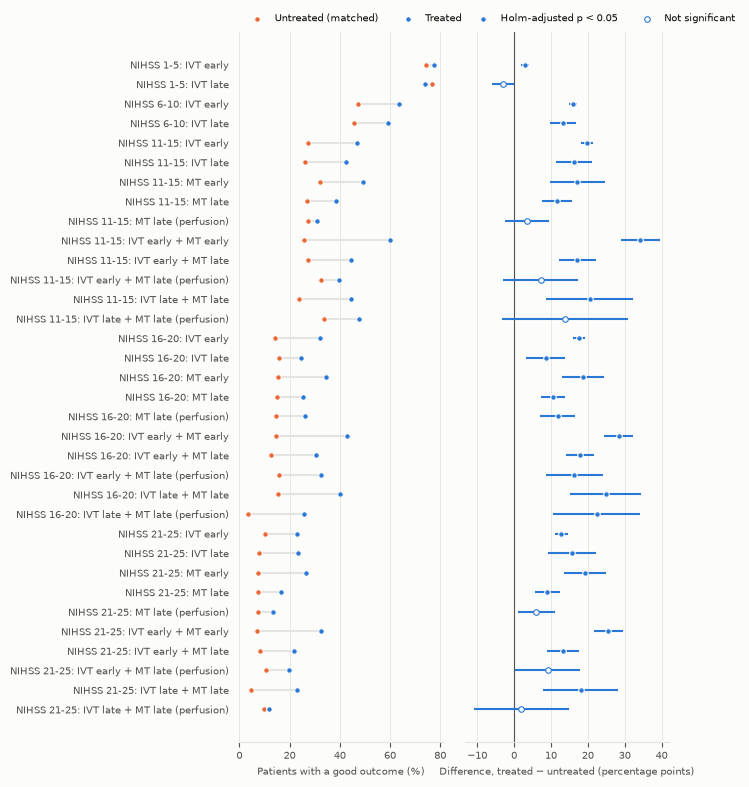

Saved table: ./output/all_ischaemic_stroke_target_trials_outcome_target_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_outcome_target_chart.png


,group_name,n_pairs,treated_events,treated_pct,untreated_events,untreated_pct,difference,ci_low,ci_high,matched_odds_ratio,or_ci_low,or_ci_high,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,10034,77.458700,9647,74.471206,2.987494,1.975473,3.999516,1.188873,1.121035,1.260815,McNemar,8.23e-09,1.65e-07
2,NIHSS 1-5: IVT late,1440,1062,73.750000,1106,76.805556,-3.055556,-6.059247,-0.051864,0.834586,0.698378,0.997360,McNemar,0.0516,0.31
4,NIHSS 6-10: IVT early,13618,8632,63.386694,6447,47.341754,16.044941,14.918177,17.171704,2.017699,1.915976,2.124823,McNemar,4.01e-162,1.36e-160
5,NIHSS 6-10: IVT late,1478,873,59.066306,677,45.805142,13.261164,9.721426,16.800901,1.723247,1.483699,2.001471,McNemar,7.07e-13,1.84e-11
7,NIHSS 11-15: IVT early,6277,2952,47.028835,1705,27.162657,19.866178,18.258254,21.474102,2.509685,2.315232,2.720470,McNemar,1.77e-118,5.83e-117
8,NIHSS 11-15: IVT late,643,273,42.457232,169,26.283048,16.174184,11.263037,21.085330,2.209302,1.712483,2.850258,McNemar,5.65e-10,1.3e-08
10,NIHSS 11-15: MT early,281,138,49.110320,90,32.028470,17.081851,9.627730,24.535971,2.297297,1.561582,3.379634,McNemar,2.09e-05,0.000272
11,NIHSS 11-15: MT late,944,364,38.559322,255,27.012712,11.546610,7.441952,15.651269,1.741497,1.421789,2.133095,McNemar,7.45e-08,1.34e-06
12,NIHSS 11-15: MT late (perfusion),426,131,30.751174,116,27.230047,3.521127,-2.528323,9.570577,1.189873,0.882222,1.604810,McNemar,0.287,0.655


In [9]:
outcome_target_results = analyse_outcome(
    "outcome_target",
    "binary",
    title="Good outcome (discharge mRS ≤ 2, or no worse than before the stroke)",
    value_label="Patients with a good outcome (%)",
)

### In-hospital death (`death`)

Binary: death in hospital. Lower is better.

**What this cell does:** Runs the analysis for death in hospital in every trial group, then saves and displays the results table and chart.

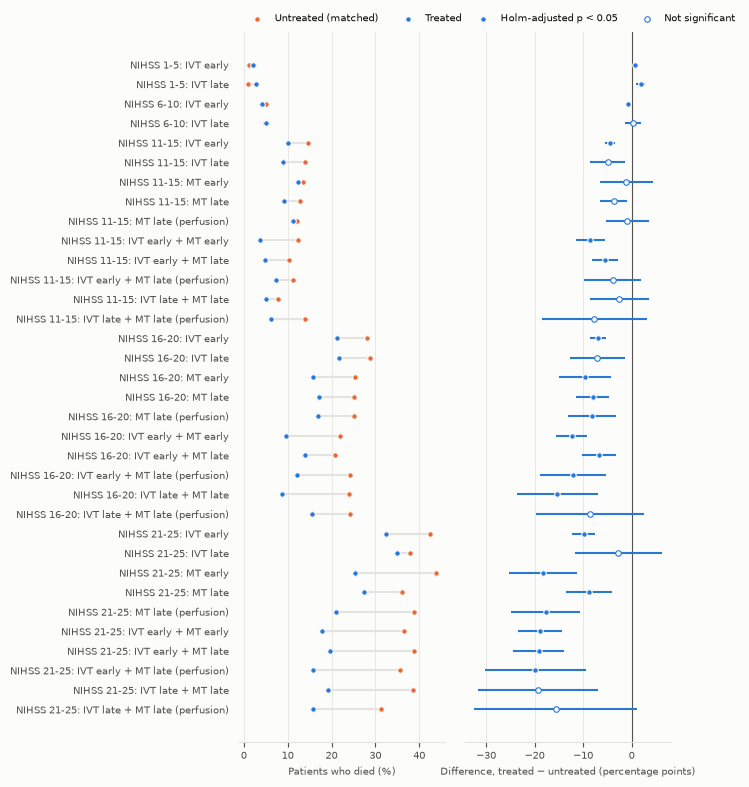

Saved table: ./output/all_ischaemic_stroke_target_trials_death_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_death_chart.png


,group_name,n_pairs,treated_events,treated_pct,untreated_events,untreated_pct,difference,ci_low,ci_high,matched_odds_ratio,or_ci_low,or_ci_high,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,260,2.007102,160,1.235140,0.771962,0.465871,1.078054,1.645161,1.347451,2.008649,McNemar,1.01e-06,2.73e-05
2,NIHSS 1-5: IVT late,1440,41,2.847222,14,0.972222,1.875000,0.907473,2.842527,3.250000,1.701711,6.206988,McNemar,0.000272,0.00571
4,NIHSS 6-10: IVT early,13618,578,4.244382,683,5.015421,-0.771038,-1.266340,-0.275737,0.837209,0.746764,0.938608,McNemar,0.00252,0.0353
5,NIHSS 6-10: IVT late,1478,75,5.074425,71,4.803789,0.270636,-1.298916,1.840188,1.058824,0.760121,1.474906,McNemar,0.8,1
7,NIHSS 11-15: IVT early,6277,639,10.180022,920,14.656683,-4.476661,-5.578256,-3.375065,0.634590,0.566538,0.710817,McNemar,2.85e-15,9.39e-14
8,NIHSS 11-15: IVT late,643,58,9.020218,90,13.996890,-4.976672,-8.486932,-1.466412,0.614458,0.433553,0.870847,McNemar,0.00741,0.0889
10,NIHSS 11-15: MT early,281,35,12.455516,38,13.523132,-1.067616,-6.433385,4.298154,0.903226,0.541840,1.505641,McNemar,0.795,1
11,NIHSS 11-15: MT late,944,86,9.110169,121,12.817797,-3.707627,-6.429716,-0.985538,0.663462,0.489383,0.899461,McNemar,0.00974,0.107
12,NIHSS 11-15: MT late (perfusion),426,48,11.267606,52,12.206573,-0.938967,-5.356320,3.478385,0.916667,0.608909,1.379973,McNemar,0.754,1


In [10]:
death_results = analyse_outcome(
    "death",
    "binary",
    title="Death",
    value_label="Patients who died (%)",
)

### Discharge disability (`discharge_disability`)

Continuous: modified Rankin Scale at discharge (0-6). Lower is better. As mRS is ordinal, the Wilcoxon signed-rank test is the primary test.

**What this cell does:** Runs the analysis for disability at discharge (mRS, from 0 for no symptoms to 6 for death) in every trial group, comparing the average mRS of treated patients with that of their matched controls, then saves and displays the results table and chart.

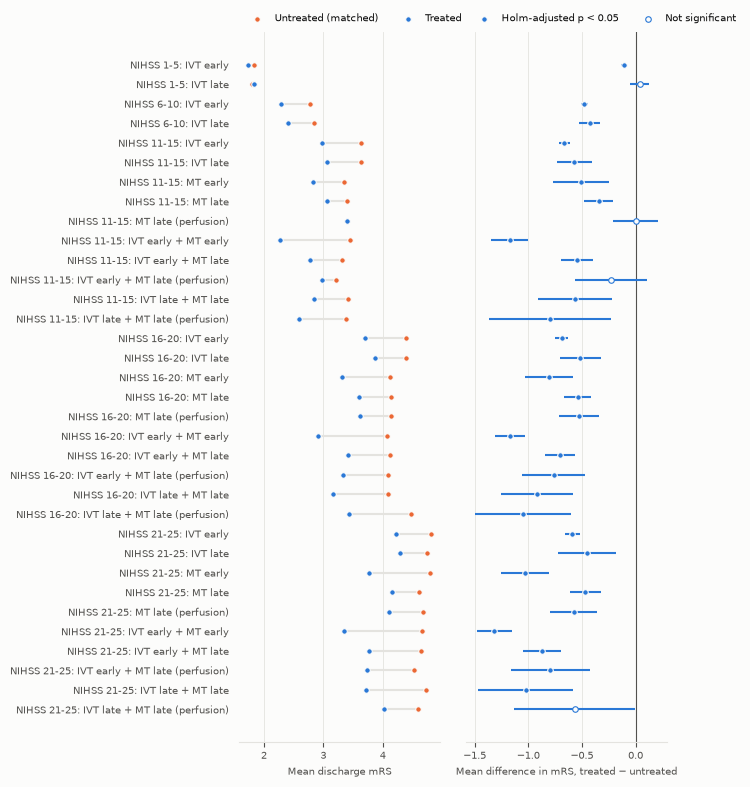

Saved table: ./output/all_ischaemic_stroke_target_trials_discharge_disability_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_discharge_disability_chart.png


,group_name,n_pairs,treated_mean,treated_sd,treated_median,treated_q1,treated_q3,untreated_mean,untreated_sd,untreated_median,untreated_q1,untreated_q3,difference,ci_low,ci_high,test,p_value,p_value_paired_t,p_value_holm
group_id,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12954,1.728810,1.370699,2.000000,1.000000,3.000000,1.838274,1.321136,2.000000,1.000000,3.000000,-0.109464,-0.139229,-0.079699,Wilcoxon signed-rank,1.81e-14,5.96e-13,3.99e-13
2,NIHSS 1-5: IVT late,1440,1.830556,1.430011,2.000000,1.000000,3.000000,1.792361,1.279256,2.000000,1.000000,3.000000,0.038194,-0.052083,0.128472,Wilcoxon signed-rank,0.574,0.407,1
4,NIHSS 6-10: IVT early,13618,2.293435,1.532096,2.000000,1.000000,3.000000,2.773094,1.470796,3.000000,2.000000,4.000000,-0.479659,-0.512000,-0.447319,Wilcoxon signed-rank,5.12e-177,2.47e-180,1.74e-175
5,NIHSS 6-10: IVT late,1478,2.407307,1.562683,2.000000,1.000000,3.000000,2.836265,1.427645,3.000000,2.000000,4.000000,-0.428958,-0.529016,-0.328900,Wilcoxon signed-rank,9.26e-17,9.58e-17,2.32e-15
7,NIHSS 11-15: IVT early,6277,2.973236,1.698681,3.000000,2.000000,4.000000,3.638522,1.532150,4.000000,3.000000,5.000000,-0.665286,-0.716770,-0.613802,Wilcoxon signed-rank,1.7e-127,7.04e-135,5.61e-126
8,NIHSS 11-15: IVT late,643,3.063764,1.658728,3.000000,2.000000,4.000000,3.636081,1.533044,4.000000,3.000000,5.000000,-0.572317,-0.736829,-0.407805,Wilcoxon signed-rank,2.46e-11,1.96e-11,4.68e-10
10,NIHSS 11-15: MT early,281,2.832740,1.699936,3.000000,2.000000,4.000000,3.341637,1.680989,3.000000,2.000000,4.000000,-0.508897,-0.772060,-0.245734,Wilcoxon signed-rank,8.44e-05,0.000173,0.000675
11,NIHSS 11-15: MT late,944,3.055085,1.576314,3.000000,2.000000,4.000000,3.399364,1.594809,3.000000,2.000000,4.000000,-0.344280,-0.480502,-0.208058,Wilcoxon signed-rank,3.63e-07,8.36e-07,5.08e-06
12,NIHSS 11-15: MT late (perfusion),426,3.394366,1.590965,4.000000,2.000000,4.000000,3.394366,1.559598,3.000000,2.000000,4.000000,0.000000,-0.210374,0.210374,Wilcoxon signed-rank,0.695,1,1


In [11]:
discharge_disability_results = analyse_outcome(
    "discharge_disability",
    "continuous",
    title="Discharge disability (mRS, lower is better)",
    value_label="Mean discharge mRS",
    diff_label="Mean difference in mRS, treated − untreated",
)

### Length of stay (`length_of_stay`)

Continuous, in days. Length of stay is right-skewed, so the Wilcoxon signed-rank test is the primary test. Patients who died in hospital are included.

**What this cell does:** Runs the analysis for length of hospital stay in every trial group, comparing the average number of days in hospital (counted to death for patients who died) between treated patients and their matched controls, then saves and displays the results table and chart.

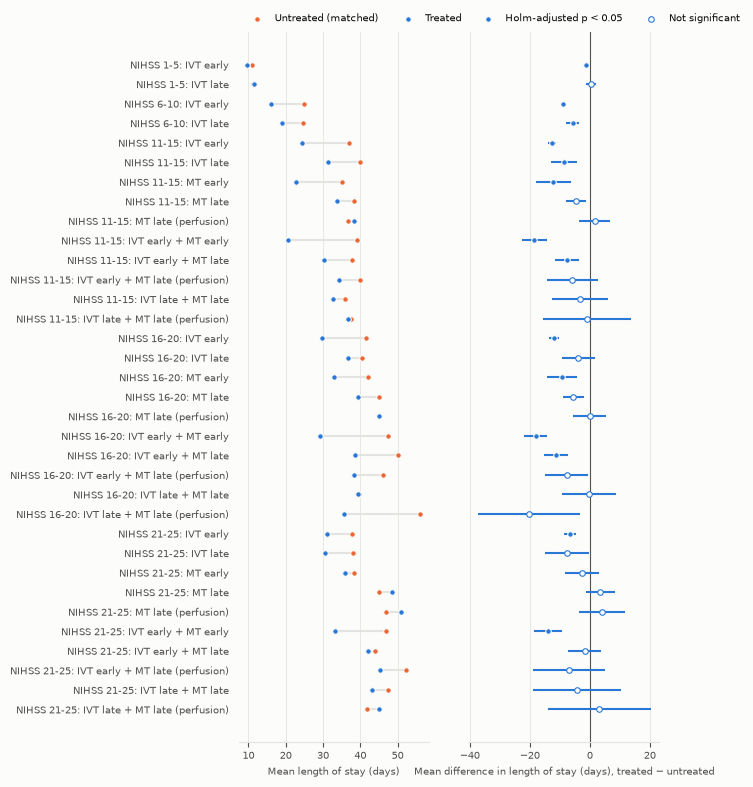

Saved table: ./output/all_ischaemic_stroke_target_trials_length_of_stay_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_length_of_stay_chart.png


,group_name,n_pairs,treated_mean,treated_sd,treated_median,treated_q1,treated_q3,untreated_mean,untreated_sd,untreated_median,untreated_q1,untreated_q3,difference,ci_low,ci_high,test,p_value,p_value_paired_t,p_value_holm
group_id,,,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12950,9.704093,19.329757,3.000000,2.000000,8.000000,10.902085,20.201254,4.000000,2.000000,10.000000,-1.197992,-1.672108,-0.723876,Wilcoxon signed-rank,1.69e-13,7.4e-07,4.72e-12
2,NIHSS 1-5: IVT late,1440,11.571528,22.986303,3.000000,2.000000,10.000000,11.166667,20.928250,3.000000,2.000000,10.000000,0.404861,-1.196265,2.005987,Wilcoxon signed-rank,0.492,0.62,1
4,NIHSS 6-10: IVT early,13616,16.077703,26.469084,5.000000,2.000000,18.000000,24.984504,31.552352,13.000000,5.000000,34.000000,-8.906801,-9.596155,-8.217447,Wilcoxon signed-rank,3.47e-238,2.57e-138,1.18e-236
5,NIHSS 6-10: IVT late,1478,19.006089,27.325602,7.000000,3.000000,24.000000,24.688769,31.680925,13.000000,4.000000,33.750000,-5.682679,-7.798075,-3.567284,Wilcoxon signed-rank,1.97e-11,1.57e-07,5.33e-10
7,NIHSS 11-15: IVT early,6274,24.400861,32.174274,11.000000,4.000000,34.000000,37.069015,37.783342,25.000000,9.000000,54.000000,-12.668154,-13.899192,-11.437116,Wilcoxon signed-rank,9.69e-113,9.74e-88,3.2e-111
8,NIHSS 11-15: IVT late,643,31.337481,38.407549,17.000000,5.000000,46.000000,40.020218,38.705026,28.000000,10.000000,58.500000,-8.682737,-12.950522,-4.414953,Wilcoxon signed-rank,1.18e-06,7.22e-05,2.83e-05
10,NIHSS 11-15: MT early,281,22.836299,29.972992,10.000000,5.000000,30.000000,35.028470,39.543727,21.000000,8.000000,53.000000,-12.192171,-17.941680,-6.442661,Wilcoxon signed-rank,3.06e-05,3.99e-05,0.000673
11,NIHSS 11-15: MT late,944,33.619703,37.412726,19.500000,6.000000,50.000000,38.268008,39.318360,25.000000,8.000000,58.000000,-4.648305,-8.060227,-1.236384,Wilcoxon signed-rank,0.0178,0.00763,0.321
12,NIHSS 11-15: MT late (perfusion),426,38.241784,39.734830,26.000000,8.000000,54.750000,36.582160,41.599820,23.000000,8.000000,54.750000,1.659624,-3.471129,6.790378,Wilcoxon signed-rank,0.291,0.525,1


In [12]:
length_of_stay_results = analyse_outcome(
    "length_of_stay",
    "continuous",
    title="Length of stay (days)",
    value_label="Mean length of stay (days)",
    diff_label="Mean difference in length of stay (days), treated − untreated",
)

### Discharge destination (`discharge_destination`)

Categorical. Destinations recorded as "missing" are treated as missing data, so those pairs are dropped.

**What this cell does:** Runs the analysis for discharge destination in every trial group, comparing the mix of destinations (home, home with community team or early supported discharge, another hospital team, care home, elsewhere, or died) between treated patients and their matched controls, then saves and displays the results table and chart.

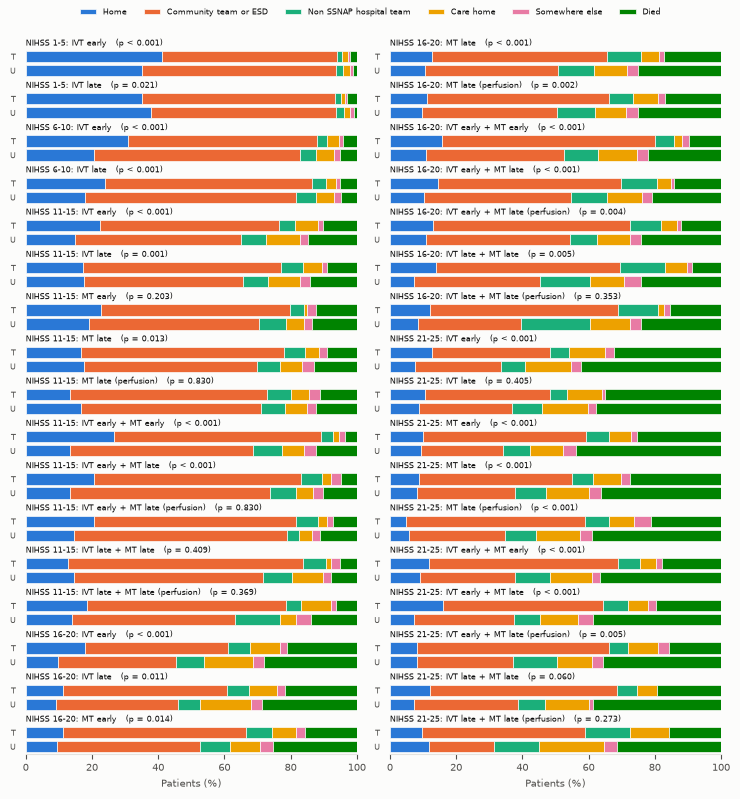

Saved table: ./output/all_ischaemic_stroke_target_trials_discharge_destination_stats.csv
Saved chart: ./output/all_ischaemic_stroke_target_trials_discharge_destination_chart.png


,group_name,n_pairs,treated_pct_home,treated_pct_community_team_or_esd,treated_pct_non_ssnap_hospital_team,treated_pct_care_home,treated_pct_somewhere_else,treated_pct_died,untreated_pct_home,untreated_pct_community_team_or_esd,untreated_pct_non_ssnap_hospital_team,untreated_pct_care_home,untreated_pct_somewhere_else,untreated_pct_died,test,p_value,p_value_holm
group_id,,,,,,,,,,,,,,,,,
1,NIHSS 1-5: IVT early,12952,41.260037,52.640519,1.683138,1.605930,0.802965,2.007412,35.137431,58.608709,2.177270,1.922483,0.918777,1.235330,Stuart-Maxwell,0,0
2,NIHSS 1-5: IVT late,1440,35.138889,58.263889,1.736111,1.250000,0.763889,2.847222,37.777778,56.041667,2.152778,1.944444,1.111111,0.972222,Stuart-Maxwell,0.0021,0.021
4,NIHSS 6-10: IVT early,13617,31.012705,56.884776,2.966880,3.818756,1.072189,4.244694,20.724095,61.974003,4.817508,5.728134,1.747815,5.008445,Stuart-Maxwell,0,0
5,NIHSS 6-10: IVT late,1478,24.086604,62.449256,4.127199,3.179973,1.082544,5.074425,17.997294,63.599459,6.156969,5.209743,2.232747,4.803789,Stuart-Maxwell,3.26e-06,6.53e-05
7,NIHSS 11-15: IVT early,6277,22.542616,54.038553,4.731560,6.945993,1.561255,10.180022,14.831926,50.183209,7.678827,10.259678,2.389677,14.656683,Stuart-Maxwell,0,0
8,NIHSS 11-15: IVT late,643,17.262830,59.720062,6.687403,5.909798,1.399689,9.020218,17.573872,47.900467,7.776050,9.486781,3.265941,13.996890,Stuart-Maxwell,7.48e-05,0.00135
10,NIHSS 11-15: MT early,281,22.775801,56.939502,4.270463,1.067616,2.491103,12.455516,19.217082,51.245552,8.185053,5.338078,2.491103,13.523132,Stuart-Maxwell,0.0254,0.203
11,NIHSS 11-15: MT late,944,16.843220,61.122881,6.250000,4.343220,2.330508,9.110169,17.478814,52.224576,7.203390,6.567797,3.707627,12.817797,Stuart-Maxwell,0.0011,0.0133
12,NIHSS 11-15: MT late (perfusion),426,13.380282,59.624413,7.042254,5.399061,3.286385,11.267606,16.666667,54.460094,7.276995,6.572770,2.816901,12.206573,Stuart-Maxwell,0.625,0.83


In [13]:
discharge_destination_results = analyse_outcome(
    "discharge_destination",
    "categorical",
    title="Discharge destination",
    category_order=[
        "home",
        "community_team_or_esd",
        "non_ssnap_hospital_team",
        "care_home",
        "somewhere_else",
        "died",
    ],
)

## Flow diagram

Numbers of patients at each step, from the cleaned SSNAP data to the matched pairs analysed. Exclusions before the study population are recounted from `cleaned_data.csv` in the same order as the filtering above, and checked against `data`. Later counts come from `data` and the matching summary. The diagram is saved to `output/` (PNG), with the counts as a CSV. A table of missing outcome data by arm in the matched pairs follows.

**What this cell does:** Counts how many patients were included or excluded at each step, from the full cleaned data to the matched pairs analysed for each outcome, and checks that these counts agree with the study population. It then draws the counts as a flow diagram (similar to a CONSORT diagram) and saves the diagram and the counts.

,n
cleaned_data,452863
excluded_no_discharge_mrs,14274
excluded_haemorrhage,54224
excluded_stroke_type_missing,0
excluded_ivt_after_mt,31
study_population,384334
excluded_nihss_0,30191
excluded_nihss_over_max,7636
excluded_nihss_missing,2768
in_nihss_bands,343739


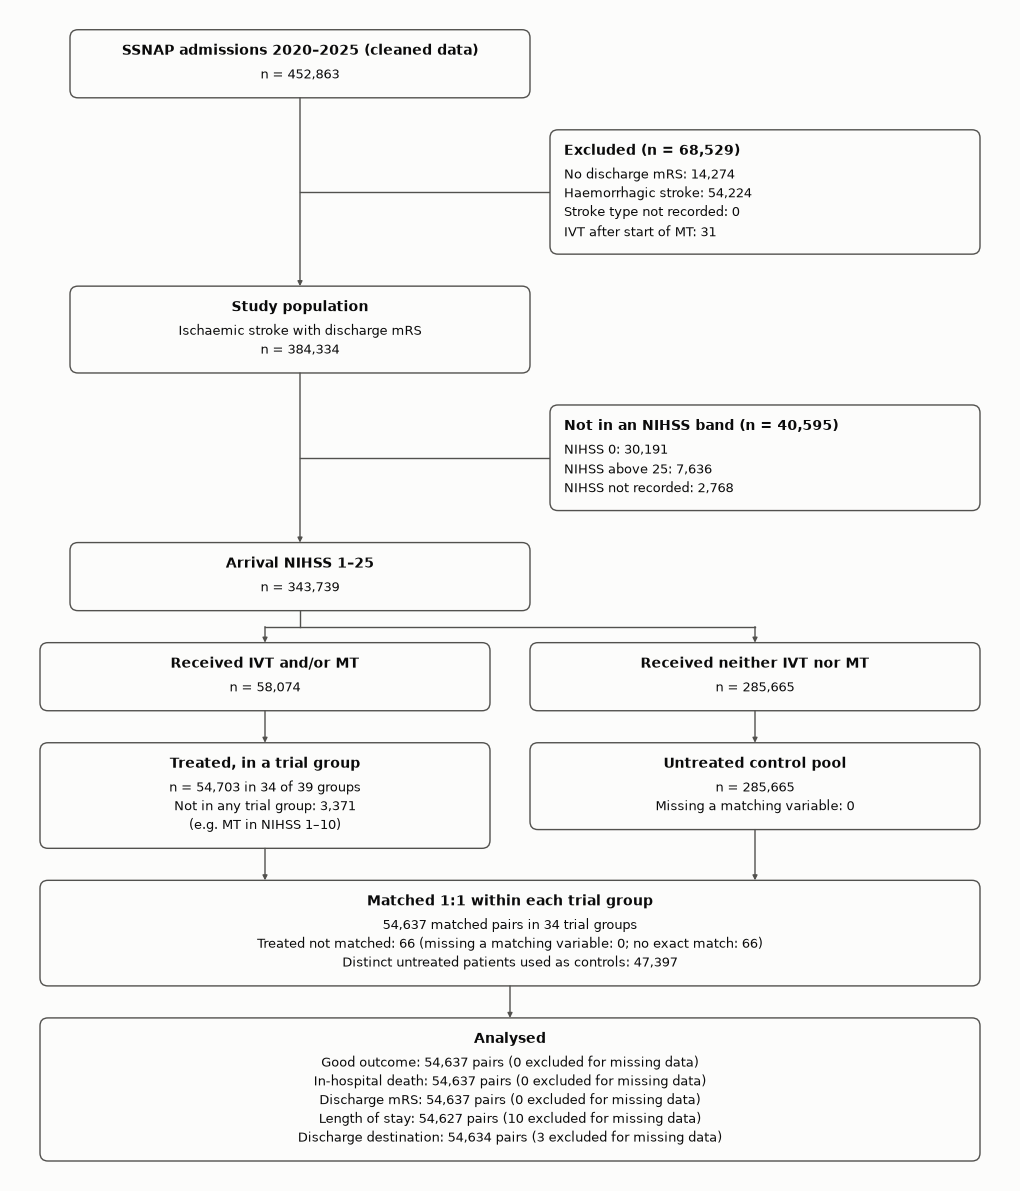

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --- Exclusions before the study population (same order as the data loading cell) ---
flow_raw = pd.read_csv(
    "../data/sam3/cleaned_data.csv",
    usecols=["discharge_disability", "infarction",
             "onset_to_thrombolysis_time", "onset_to_thrombectomy_time"],
    low_memory=False,
)
n_cleaned = len(flow_raw)
step = flow_raw.dropna(subset=["discharge_disability"])
n_no_mrs = n_cleaned - len(step)
n_haemorrhage = int((step["infarction"] == 0).sum())
n_type_missing = int(step["infarction"].isna().sum())
step = step[step["infarction"] == 1]
ivt_after_mt = step["onset_to_thrombolysis_time"] > step["onset_to_thrombectomy_time"]
n_ivt_after_mt = int(ivt_after_mt.sum())
step = step[~ivt_after_mt]
n_study = len(step)
assert n_study == len(data), "Flow counts do not match the study population in `data`"

# --- NIHSS bands ---
nihss = pd.to_numeric(data["stroke_severity"], errors="coerce")
out_of_band = data["stroke_severity_band"].isna()
n_nihss_0 = int((out_of_band & (nihss == 0)).sum())
n_nihss_over = int((out_of_band & (nihss > severity_bands["NIHSS Max"].max())).sum())
n_nihss_missing = int((out_of_band & nihss.isna()).sum())
n_out_of_band = int(out_of_band.sum())
in_band = ~out_of_band
n_in_band = int(in_band.sum())

# --- Treated and untreated within bands ---
is_untreated = (data[TREATMENT_FLAGS] == 0).all(axis=1)
n_treated_band = int((in_band & ~is_untreated).sum())
n_untreated_band = int((in_band & is_untreated).sum())
n_untreated_incomplete = int((in_band & is_untreated & ~complete_matching_data).sum())
n_untreated_pool = n_untreated_band - n_untreated_incomplete

n_in_groups = int(match_summary["n_treated"].sum())
n_not_in_group = n_treated_band - n_in_groups
n_missing_matching = int(match_summary["n_treated_missing_matching_data"].sum())
n_matched = int(match_summary["n_matched"].sum())
n_no_match = n_in_groups - n_missing_matching - n_matched
n_groups_defined = len(match_summary)
n_groups_with_pairs = int((match_summary["n_matched"] > 0).sum())
n_controls_distinct = int(matched_data.loc[matched_data["treated"] == 0, "patient_id"].nunique())

flow_counts = pd.Series({
    "cleaned_data": n_cleaned,
    "excluded_no_discharge_mrs": n_no_mrs,
    "excluded_haemorrhage": n_haemorrhage,
    "excluded_stroke_type_missing": n_type_missing,
    "excluded_ivt_after_mt": n_ivt_after_mt,
    "study_population": n_study,
    "excluded_nihss_0": n_nihss_0,
    "excluded_nihss_over_max": n_nihss_over,
    "excluded_nihss_missing": n_nihss_missing,
    "in_nihss_bands": n_in_band,
    "treated_in_bands": n_treated_band,
    "treated_not_in_any_trial_group": n_not_in_group,
    "treated_in_trial_groups": n_in_groups,
    "treated_missing_matching_data": n_missing_matching,
    "treated_no_exact_match": n_no_match,
    "matched_pairs": n_matched,
    "trial_groups_defined": n_groups_defined,
    "trial_groups_with_pairs": n_groups_with_pairs,
    "untreated_in_bands": n_untreated_band,
    "untreated_missing_matching_data": n_untreated_incomplete,
    "untreated_pool": n_untreated_pool,
    "distinct_untreated_controls_used": n_controls_distinct,
}, name="n")
flow_counts.to_csv(f"{OUTPUT_DIR}/{prefix}_flow_counts.csv")
display(flow_counts.to_frame())


# --- Draw the diagram ---
# Units are inches (the axes fill the figure), so text can be measured and each box
# sized to fit its text. Boxes are stacked from the top so they cannot overlap.
from types import SimpleNamespace

FLOW_FIG_WIDTH, FLOW_FIG_MAX_HEIGHT = 10.0, 20.0
FLOW_PAD = 0.14        # inside each box, inches
FLOW_TITLE_GAP = 0.07  # between box title and body
FLOW_GAP = 0.32        # between boxes

fig = plt.figure(figsize=(FLOW_FIG_WIDTH, FLOW_FIG_MAX_HEIGHT))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, FLOW_FIG_WIDTH)
ax.set_ylim(0, FLOW_FIG_MAX_HEIGHT)
ax.axis("off")
renderer = fig.canvas.get_renderer()


def _extent(text_artist):
    return text_artist.get_window_extent(renderer).transformed(ax.transData.inverted())


def flow_box(x, top, title, body="", width=4.0, align="center"):
    """Box with its top edge at `top`, centred on `x`, grown to fit its text."""
    t1 = ax.text(0, 0, title, ha=align, va="top", fontsize=10, fontweight="bold", color=TEXT_PRIMARY)
    t2 = (ax.text(0, 0, body, ha=align, va="top", fontsize=9, color=TEXT_PRIMARY, linespacing=1.5)
          if body else None)
    e1 = _extent(t1)
    e2 = _extent(t2) if t2 is not None else None
    width = max(width, e1.width + 2 * FLOW_PAD, (e2.width + 2 * FLOW_PAD) if e2 is not None else 0)
    left = x - width / 2
    tx = x if align == "center" else left + FLOW_PAD
    t1.set_position((tx, top - FLOW_PAD))
    height = 2 * FLOW_PAD + e1.height
    if t2 is not None:
        t2.set_position((tx, top - FLOW_PAD - e1.height - FLOW_TITLE_GAP))
        height += FLOW_TITLE_GAP + e2.height
    bottom = top - height
    ax.add_patch(FancyBboxPatch((left, bottom), width, height,
                                boxstyle="round,pad=0,rounding_size=0.08",
                                linewidth=1, edgecolor=TEXT_SECONDARY, facecolor=SURFACE, zorder=1))
    for t in (t1, t2):
        if t is not None:
            t.set_zorder(2)
    return SimpleNamespace(top=top, bottom=bottom, left=left, right=left + width, mid=(top + bottom) / 2)


def flow_arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=TEXT_SECONDARY, lw=1, shrinkA=0, shrinkB=0))


def flow_line(xs, ys):
    ax.plot(xs, ys, color=TEXT_SECONDARY, lw=1, zorder=0)


f = lambda n: f"{n:,}"
top_y = FLOW_FIG_MAX_HEIGHT - 0.2
main_x, side_x = 2.9, 7.55      # main column and exclusion boxes
left_x, right_x = 2.55, 7.45    # treated and untreated columns
centre_x = FLOW_FIG_WIDTH / 2

a = flow_box(main_x, top_y, "SSNAP admissions 2020–2025 (cleaned data)", f"n = {f(n_cleaned)}", width=4.6)
e1 = flow_box(side_x, a.bottom - FLOW_GAP, f"Excluded (n = {f(n_cleaned - n_study)})",
              f"No discharge mRS: {f(n_no_mrs)}\nHaemorrhagic stroke: {f(n_haemorrhage)}\n"
              f"Stroke type not recorded: {f(n_type_missing)}\nIVT after start of MT: {f(n_ivt_after_mt)}",
              width=4.3, align="left")
b = flow_box(main_x, e1.bottom - FLOW_GAP, "Study population",
             f"Ischaemic stroke with discharge mRS\nn = {f(n_study)}", width=4.6)
flow_arrow(main_x, a.bottom, main_x, b.top)
flow_line([main_x, e1.left], [e1.mid, e1.mid])

e2 = flow_box(side_x, b.bottom - FLOW_GAP, f"Not in an NIHSS band (n = {f(n_out_of_band)})",
              f"NIHSS 0: {f(n_nihss_0)}\nNIHSS above {severity_bands['NIHSS Max'].max()}: {f(n_nihss_over)}\n"
              f"NIHSS not recorded: {f(n_nihss_missing)}", width=4.3, align="left")
c = flow_box(main_x, e2.bottom - FLOW_GAP, "Arrival NIHSS 1–25", f"n = {f(n_in_band)}", width=4.6)
flow_arrow(main_x, b.bottom, main_x, c.top)
flow_line([main_x, e2.left], [e2.mid, e2.mid])

split_y = c.bottom - FLOW_GAP / 2
row_top = c.bottom - FLOW_GAP
d1 = flow_box(left_x, row_top, "Received IVT and/or MT", f"n = {f(n_treated_band)}", width=4.5)
d2 = flow_box(right_x, row_top, "Received neither IVT nor MT", f"n = {f(n_untreated_band)}", width=4.5)
flow_line([main_x, main_x], [c.bottom, split_y])
flow_line([left_x, right_x], [split_y, split_y])
flow_arrow(left_x, split_y, left_x, d1.top)
flow_arrow(right_x, split_y, right_x, d2.top)

row_top = min(d1.bottom, d2.bottom) - FLOW_GAP
g = flow_box(left_x, row_top, "Treated, in a trial group",
             f"n = {f(n_in_groups)} in {n_groups_with_pairs} of {n_groups_defined} groups\n"
             f"Not in any trial group: {f(n_not_in_group)}\n(e.g. MT in NIHSS 1–10)", width=4.5)
p = flow_box(right_x, row_top, "Untreated control pool",
             f"n = {f(n_untreated_pool)}\nMissing a matching variable: {f(n_untreated_incomplete)}", width=4.5)
flow_arrow(left_x, d1.bottom, left_x, g.top)
flow_arrow(right_x, d2.bottom, right_x, p.top)

m = flow_box(centre_x, min(g.bottom, p.bottom) - FLOW_GAP, "Matched 1:1 within each trial group",
             f"{f(n_matched)} matched pairs in {n_groups_with_pairs} trial groups\n"
             f"Treated not matched: {f(n_in_groups - n_matched)} "
             f"(missing a matching variable: {f(n_missing_matching)}; no exact match: {f(n_no_match)})\n"
             f"Distinct untreated patients used as controls: {f(n_controls_distinct)}", width=9.4)
flow_arrow(left_x, g.bottom, left_x, m.top)
flow_arrow(right_x, p.bottom, right_x, m.top)

# Pairs analysed per outcome (pairs dropped if either patient is missing the outcome)
analysed_lines = []
for outcome, label in [("outcome_target", "Good outcome"), ("death", "In-hospital death"),
                       ("discharge_disability", "Discharge mRS"), ("length_of_stay", "Length of stay"),
                       ("discharge_destination", "Discharge destination")]:
    values = matched_data[outcome]
    if outcome == "discharge_destination":
        values = values.where(~values.isin(MISSING_CATEGORIES))
    missing_pair = (matched_data.assign(_m=values.isna())
                    .groupby(["group_id", "pair_id"])["_m"].any())
    analysed_lines.append(f"{label}: {f(int((~missing_pair).sum()))} pairs "
                          f"({f(int(missing_pair.sum()))} excluded for missing data)")
an = flow_box(centre_x, m.bottom - FLOW_GAP, "Analysed", "\n".join(analysed_lines), width=9.4)
flow_arrow(centre_x, m.bottom, centre_x, an.top)

# Trim the unused space below the last box (1 unit stays 1 inch)
used_height = FLOW_FIG_MAX_HEIGHT - (an.bottom - 0.2)
fig.set_size_inches(FLOW_FIG_WIDTH, used_height)
ax.set_ylim(FLOW_FIG_MAX_HEIGHT - used_height, FLOW_FIG_MAX_HEIGHT)

fig.savefig(f"{OUTPUT_DIR}/{prefix}_flow_diagram.png", dpi=SAVE_DPI)
plt.show()


**What this cell does:** Counts how many treated and how many untreated patients in the matched pairs are missing each outcome, and saves the table. This is needed for the TARGET reporting checklist.

In [15]:
# Missing outcome data by arm, in the matched pairs (before pairs are dropped)
missing_rows = []
for outcome in OUTCOME_FEATURES:
    values = matched_data[outcome]
    if outcome == "discharge_destination":
        values = values.where(~values.isin(MISSING_CATEGORIES))
    for arm, label in [(1, "treated"), (0, "untreated")]:
        in_arm = matched_data["treated"] == arm
        missing_rows.append({"outcome": outcome, "arm": label,
                             "n_patients": int(in_arm.sum()),
                             "n_missing": int(values[in_arm].isna().sum())})
missing_by_arm = pd.DataFrame(missing_rows).pivot(index="outcome", columns="arm",
                                                  values=["n_patients", "n_missing"])
missing_by_arm.to_csv(f"{OUTPUT_DIR}/{prefix}_missing_outcomes_by_arm.csv")
display(missing_by_arm)

n_patients           n_missing          
arm                      treated untreated   treated untreated
outcome                                                       
death                      54637     54637         0         0
discharge_destination      54637     54637         1         2
discharge_disability       54637     54637         0         0
length_of_stay             54637     54637         4         6
outcome_target             54637     54637         0         0

## Sensitivity analyses

These analyses test how robust the main estimates are to the main design choices and to unmeasured confounding. Each repeats the target trials with one change and reports good outcome, in-hospital death and discharge disability, with Holm adjustment across trial groups within each analysis and outcome. Results are compared with the primary analysis in one table and two charts.

1. **Exact NIHSS.** Match on exact arrival NIHSS score as well as the five primary matching variables, to remove the imbalance in severity within NIHSS bands.
2. **More covariates.** Also match on sex, hypertension, diabetes and congestive heart failure (the characteristics not used in the primary matching).
3. **Known onset time.** Restrict both arms to patients with a known onset time, so that late groups contain only treatment known to be late.
4. **Large-vessel occlusion (MT groups).** In groups that include MT, restrict both arms to patients with a recorded large-vessel occlusion (LVO), so that controls have the same type of stroke as treated patients. IVT-only groups are not repeated.
5. **Landmark at 1 day.** Using the primary matched pairs, keep only pairs in which both patients were still in hospital 1 day after arrival. This removes pairs affected by very early death or discharge, a crude check on immortal time bias.
6. **Length of stay in survivors.** Length of stay in pairs where both patients survived to discharge, separating effects on recovery from effects on survival.
7. **E-values.** For good outcome and in-hospital death in the primary analysis, the E-value is the minimum strength of association (risk ratio) that an unmeasured confounder would need with both treatment and outcome to fully explain away the estimate (VanderWeele and Ding, 2017). An E-value for the confidence limit closest to the null is also given.
8. **Sensemakr.** Cinelli and Hazlett's robustness values and benchmark bounds for good outcome and in-hospital death, from a linear probability model in each group's matched pairs.

Analyses 1 to 4 repeat the matching, so their matched populations and random pairing differ from the primary analysis. Matching rates are reported for each.

**What this cell does:** Prepares the sensitivity analyses; it does not produce results itself, apart from recalculating the main analysis in the same format for comparison. It adds two extra fields from the cleaned data (whether the onset time was known, and whether a large-vessel occlusion was recorded), and defines functions to repeat the matching with different settings, to repeat the outcome analyses, and to keep only pairs that meet a condition.

In [16]:
# Sensitivity analyses: set-up and helper functions

# Columns needed for sensitivity analyses that are not in ALL_FEATURES.
# `data` keeps the row index of cleaned_data.csv, so these are joined on the index.
SENS_EXTRA_COLUMNS = ["onset_known", "lvo"]
sens_extra = pd.read_csv("../data/sam3/cleaned_data.csv", usecols=SENS_EXTRA_COLUMNS, low_memory=False)
sens_data = data.join(sens_extra, how="left")

# Outcomes repeated in each sensitivity analysis
SENS_OUTCOMES = {
    "outcome_target": "binary",
    "death": "binary",
    "discharge_disability": "continuous",
}
SENS_OUTCOME_LABELS = {
    "outcome_target": "Good outcome (difference, percentage points)",
    "death": "In-hospital death (difference, percentage points)",
    "discharge_disability": "Discharge mRS (mean difference)",
    "length_of_stay": "Length of stay (mean difference, days)",
}
LANDMARK_DAYS = 1


def group_has_mt(group):
    return group["MT<=270"] == 1 or group["MT>270"] == 1


def match_trial_groups(df, matching_features, restrict=None, seed=RANDOM_SEED):
    """Repeat the matching for every trial group.

    `matching_features` replaces MATCHING_FEATURES. `restrict(df, group)` returns a
    boolean Series of patients eligible for that group (applied to both arms), or
    None to skip the group. Returns (matched data, matching summary).
    """
    rng = np.random.default_rng(seed)
    is_untreated = (df[TREATMENT_FLAGS] == 0).all(axis=1)
    complete = df[matching_features].notna().all(axis=1)
    matched, summary = [], []

    for _, group in treatment_groups_df.iterrows():
        band = f"{group['NIHSS Min']}-{group['NIHSS Max']}"
        eligible = df["stroke_severity_band"] == band
        if restrict is not None:
            keep = restrict(df, group)
            if keep is None:
                continue
            eligible &= keep.fillna(False).astype(bool)

        has_late_treatment = group["IVT>270"] == 1 or group["MT>270"] == 1
        is_treated = eligible.copy()
        for sheet_col, data_col in GROUP_PATTERN_COLUMNS.items():
            if sheet_col == "Perfusion imaging" and not has_late_treatment:
                continue
            is_treated &= df[data_col] == group[sheet_col]

        controls = df[eligible & is_untreated & complete]
        pairs = exact_match(df[is_treated & complete], controls, matching_features, rng)

        n_treated = int(is_treated.sum())
        summary.append({
            "group_id": group["Group ID"],
            "group_name": group["Group name"],
            "n_treated": n_treated,
            "n_matched": len(pairs),
            "pct_treated_matched": round(100 * len(pairs) / n_treated, 1) if n_treated else np.nan,
        })
        if len(pairs) == 0:
            continue

        pair_id = np.arange(len(pairs))
        group_matched = pd.concat([
            df.loc[pairs["treated_id"]].assign(treated=1, pair_id=pair_id),
            df.loc[pairs["control_id"]].assign(treated=0, pair_id=pair_id),
        ]).rename_axis("patient_id").reset_index()
        group_matched.insert(0, "group_id", group["Group ID"])
        group_matched.insert(1, "group_name", group["Group name"])
        matched.append(group_matched)

    return pd.concat(matched, ignore_index=True), pd.DataFrame(summary).set_index("group_id")


def analyse_scenario(matched, scenario, outcomes=SENS_OUTCOMES):
    """Paired statistics for each outcome and trial group, with Holm adjustment
    across trial groups within each outcome. Groups with fewer than 2 pairs are skipped."""
    results = []
    for outcome, outcome_type in outcomes.items():
        rows = []
        for (group_id, group_name), group_data in matched.groupby(["group_id", "group_name"]):
            wide = paired_outcome(group_data, outcome)
            if len(wide) < 2:
                continue
            stats_fn = binary_stats if outcome_type == "binary" else continuous_stats
            rows.append({"scenario": scenario, "outcome": outcome, "group_id": group_id,
                         "group_name": group_name, **stats_fn(wide)})
        res = pd.DataFrame(rows)
        if res.empty:
            continue
        res["p_value_holm"] = np.nan
        has_p = res["p_value"].notna()
        if has_p.any():
            res.loc[has_p, "p_value_holm"] = multipletests(res.loc[has_p, "p_value"], method="holm")[1]
        results.append(res)
    return pd.concat(results, ignore_index=True)


def keep_pairs(matched, pair_condition):
    """Keep whole matched pairs where `pair_condition` (a boolean column) holds for both patients."""
    ok = matched.assign(_ok=pair_condition.fillna(False).astype(bool))
    both_ok = ok.groupby(["group_id", "pair_id"])["_ok"].transform("all")
    return matched[both_ok.to_numpy()]


sensitivity_results = []
sensitivity_matching = {}

# Primary analysis, recalculated in the same format for comparison
sensitivity_results.append(analyse_scenario(matched_data, "Primary"))
print("Set-up complete.")

Set-up complete.


### 1. Exact NIHSS

**What this cell does:** Sensitivity analysis 1: repeats the matching so that each treated patient is also paired on their exact NIHSS score, not just their severity band, then repeats the analyses of good outcome, death and discharge mRS. It shows how many treated patients could still be matched.

In [17]:
matched_s, summary_s = match_trial_groups(sens_data, MATCHING_FEATURES + ["stroke_severity"])
sensitivity_matching["Exact NIHSS"] = summary_s
sensitivity_results.append(analyse_scenario(matched_s, "Exact NIHSS"))
display(summary_s)

,group_name,n_treated,n_matched,pct_treated_matched
group_id,,,,
1,NIHSS 1-5: IVT early,12954,12947,99.9
2,NIHSS 1-5: IVT late,1441,1440,99.9
3,NIHSS 1-5: IVT late (perfusion),0,0,NaN
4,NIHSS 6-10: IVT early,13620,13588,99.8
5,NIHSS 6-10: IVT late,1478,1476,99.9
6,NIHSS 6-10: IVT late (perfusion),0,0,NaN
7,NIHSS 11-15: IVT early,6289,6226,99.0
8,NIHSS 11-15: IVT late,643,642,99.8
9,NIHSS 11-15: IVT late (perfusion),0,0,NaN


### 2. More covariates

**What this cell does:** Sensitivity analysis 2: repeats the matching with sex, high blood pressure, diabetes and heart failure added to the matching characteristics, then repeats the analyses of good outcome, death and discharge mRS. It shows how many treated patients could still be matched.

In [18]:
SENS_EXTRA_MATCHING = ["male", "hypertension", "diabetes", "congestive_heart_failure"]
matched_s, summary_s = match_trial_groups(sens_data, MATCHING_FEATURES + SENS_EXTRA_MATCHING)
sensitivity_matching["More covariates"] = summary_s
sensitivity_results.append(analyse_scenario(matched_s, "More covariates"))
display(summary_s)

,group_name,n_treated,n_matched,pct_treated_matched
group_id,,,,
1,NIHSS 1-5: IVT early,12954,12939,99.9
2,NIHSS 1-5: IVT late,1441,1440,99.9
3,NIHSS 1-5: IVT late (perfusion),0,0,NaN
4,NIHSS 6-10: IVT early,13620,13518,99.3
5,NIHSS 6-10: IVT late,1478,1471,99.5
6,NIHSS 6-10: IVT late (perfusion),0,0,NaN
7,NIHSS 11-15: IVT early,6289,6071,96.5
8,NIHSS 11-15: IVT late,643,626,97.4
9,NIHSS 11-15: IVT late (perfusion),0,0,NaN


### 3. Known onset time

**What this cell does:** Sensitivity analysis 3: repeats the matching and analyses using only patients whose time of stroke onset was known, so that late treatment means treatment known to be late. It shows how many treated patients could still be matched.

In [19]:
matched_s, summary_s = match_trial_groups(
    sens_data, MATCHING_FEATURES, restrict=lambda df, group: df["onset_known"] == 1
)
sensitivity_matching["Known onset"] = summary_s
sensitivity_results.append(analyse_scenario(matched_s, "Known onset"))
display(summary_s)

,group_name,n_treated,n_matched,pct_treated_matched
group_id,,,,
1,NIHSS 1-5: IVT early,12954,12954,100.0
2,NIHSS 1-5: IVT late,1178,1177,99.9
3,NIHSS 1-5: IVT late (perfusion),0,0,NaN
4,NIHSS 6-10: IVT early,13620,13572,99.6
5,NIHSS 6-10: IVT late,1173,1173,100.0
6,NIHSS 6-10: IVT late (perfusion),0,0,NaN
7,NIHSS 11-15: IVT early,6289,6072,96.5
8,NIHSS 11-15: IVT late,505,505,100.0
9,NIHSS 11-15: IVT late (perfusion),0,0,NaN


### 4. Large-vessel occlusion (MT groups)

**What this cell does:** Sensitivity analysis 4: for trial groups that include thrombectomy, repeats the matching and analyses using only patients (treated and untreated) with a recorded large-vessel occlusion, so that the comparison is between patients with the same type of stroke. It first reports how often large-vessel occlusion is recorded.

In [20]:
print("LVO recorded in", f"{sens_data['lvo'].notna().mean():.1%}", "of patients;",
      f"{(sens_data['lvo'] == 1).mean():.1%}", "with LVO = 1")

matched_s, summary_s = match_trial_groups(
    sens_data, MATCHING_FEATURES,
    restrict=lambda df, group: (df["lvo"] == 1) if group_has_mt(group) else None,
)
sensitivity_matching["LVO (MT groups)"] = summary_s
sensitivity_results.append(analyse_scenario(matched_s, "LVO (MT groups)"))
display(summary_s)

LVO recorded in 21.3% of patients; 2.3% with LVO = 1


,group_name,n_treated,n_matched,pct_treated_matched
group_id,,,,
10,NIHSS 11-15: MT early,69,52,75.4
11,NIHSS 11-15: MT late,305,245,80.3
12,NIHSS 11-15: MT late (perfusion),57,52,91.2
13,NIHSS 11-15: IVT early + MT early,124,111,89.5
14,NIHSS 11-15: IVT early + MT late,175,156,89.1
15,NIHSS 11-15: IVT early + MT late (perfusion),22,22,100.0
16,NIHSS 11-15: IVT late + MT late,62,58,93.5
17,NIHSS 11-15: IVT late + MT late (perfusion),14,14,100.0
21,NIHSS 16-20: MT early,110,90,81.8


### 5. Landmark at 1 day

**What this cell does:** Sensitivity analysis 5: using the original matched pairs, keeps only pairs in which both patients were still in hospital at least 1 day after arrival, and repeats the analyses. This checks whether patients who died or left hospital very early, before they could be treated, are driving the results. It shows the percentage of pairs kept in each group.

In [21]:
landmark_data = keep_pairs(matched_data, matched_data["length_of_stay"] >= LANDMARK_DAYS)
pairs_before = matched_data.groupby("group_id")["pair_id"].nunique()
pairs_after = landmark_data.groupby("group_id")["pair_id"].nunique()
landmark_summary = pd.DataFrame({"pairs_primary": pairs_before, "pairs_landmark": pairs_after}).fillna(0)
landmark_summary["pct_kept"] = (100 * landmark_summary["pairs_landmark"] / landmark_summary["pairs_primary"]).round(1)
sensitivity_matching["Landmark 1 day"] = landmark_summary
sensitivity_results.append(analyse_scenario(landmark_data, "Landmark 1 day"))
display(landmark_summary)

,pairs_primary,pairs_landmark,pct_kept
group_id,,,
1,12954,12499,96.5
2,1440,1378,95.7
4,13618,13481,99.0
5,1478,1468,99.3
7,6277,6221,99.1
8,643,639,99.4
10,281,279,99.3
11,944,933,98.8
12,426,424,99.5


### 6. Length of stay in survivors

**What this cell does:** Sensitivity analysis 6: compares length of stay only in pairs in which both patients survived to discharge, and shows this next to the original length of stay results. This separates shorter stays due to faster recovery from changes in length of stay caused by fewer deaths.

In [22]:
survivor_data = keep_pairs(matched_data, matched_data["death"] == 0)
los_survivors = analyse_scenario(
    survivor_data, "Survivors", outcomes={"length_of_stay": "continuous"})
los_primary = analyse_scenario(
    matched_data, "Primary", outcomes={"length_of_stay": "continuous"})
sensitivity_results += [los_primary, los_survivors]

los_compare = los_primary.set_index("group_name")[["n_pairs", "difference", "ci_low", "ci_high"]].join(
    los_survivors.set_index("group_name")[["n_pairs", "difference", "ci_low", "ci_high", "p_value_holm"]],
    lsuffix="_all", rsuffix="_survivors",
)
display(los_compare.style.format(precision=2, na_rep="-"))

,n_pairs_all,difference_all,ci_low_all,ci_high_all,n_pairs_survivors,difference_survivors,ci_low_survivors,ci_high_survivors,p_value_holm
group_name,,,,,,,,,
NIHSS 1-5: IVT early,12950,-1.20,-1.67,-0.72,12535,-1.17,-1.65,-0.69,0.00
NIHSS 1-5: IVT late,1440,0.40,-1.20,2.01,1387,0.56,-1.07,2.18,1.00
NIHSS 6-10: IVT early,13616,-8.91,-9.60,-8.22,12394,-9.19,-9.92,-8.46,0.00
NIHSS 6-10: IVT late,1478,-5.68,-7.80,-3.57,1335,-6.25,-8.51,-3.99,0.00
NIHSS 11-15: IVT early,6274,-12.67,-13.90,-11.44,4866,-15.35,-16.79,-13.91,0.00
NIHSS 11-15: IVT late,643,-8.68,-12.95,-4.41,502,-11.62,-16.63,-6.62,0.00
NIHSS 11-15: MT early,281,-12.19,-17.94,-6.44,215,-14.89,-21.50,-8.29,0.00
NIHSS 11-15: MT late,944,-4.65,-8.06,-1.24,754,-6.76,-10.69,-2.82,0.03
NIHSS 11-15: MT late (perfusion),426,1.66,-3.47,6.79,330,0.06,-5.84,5.95,1.00


### 7. E-values

The risk ratio for matched pairs is (pairs where the treated patient had the outcome) / (pairs where the control had the outcome), with the standard error of log RR from Agresti (2013). For protective estimates (RR < 1) the reciprocal is used. The E-value for the confidence interval is 1 if the interval includes 1.

**What this cell does:** Sensitivity analysis 7: calculates E-values for good outcome and in-hospital death. For each trial group it calculates the risk ratio from the matched pairs, then the E-value: how strongly an unmeasured factor (such as frailty, or a decision not to treat actively) would need to be linked to both treatment and outcome to explain away the result. Larger E-values mean the result is harder to explain away. The table is saved.

In [23]:
def e_value(rr):
    if pd.isna(rr) or rr <= 0:
        return np.nan
    rr = rr if rr >= 1 else 1 / rr
    return rr + np.sqrt(rr * (rr - 1))


def paired_risk_ratio(wide):
    t = wide["treated"].astype(int)
    u = wide["untreated"].astype(int)
    a = int(((t == 1) & (u == 1)).sum())
    b = int(((t == 1) & (u == 0)).sum())
    c = int(((t == 0) & (u == 1)).sum())
    if (a + b) == 0 or (a + c) == 0:
        return np.nan, np.nan, np.nan
    rr = (a + b) / (a + c)
    se = np.sqrt((b + c) / ((a + b) * (a + c)))
    return rr, rr * np.exp(-1.96 * se), rr * np.exp(1.96 * se)


e_rows = []
for outcome in ["outcome_target", "death"]:
    for (group_id, group_name), group_data in matched_data.groupby(["group_id", "group_name"]):
        wide = paired_outcome(group_data, outcome)
        rr, low, high = paired_risk_ratio(wide)
        if pd.isna(rr):
            ci_limit = np.nan
        elif low <= 1 <= high:
            ci_limit = 1.0
        else:
            ci_limit = low if rr > 1 else high
        e_rows.append({
            "outcome": outcome, "group_id": group_id, "group_name": group_name,
            "n_pairs": len(wide), "risk_ratio": rr, "rr_ci_low": low, "rr_ci_high": high,
            "e_value": e_value(rr), "e_value_ci": 1.0 if ci_limit == 1.0 else e_value(ci_limit),
        })

e_values = pd.DataFrame(e_rows)
e_values.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_e_values.csv", index=False)
display(e_values.style.format(precision=2, na_rep="-"))

,outcome,group_id,group_name,n_pairs,risk_ratio,rr_ci_low,rr_ci_high,e_value,e_value_ci
0,outcome_target,1,NIHSS 1-5: IVT early,12954,1.04,1.03,1.05,1.24,1.19
1,outcome_target,2,NIHSS 1-5: IVT late,1440,0.96,0.92,1.00,1.25,1.03
2,outcome_target,4,NIHSS 6-10: IVT early,13618,1.34,1.31,1.37,2.01,1.95
3,outcome_target,5,NIHSS 6-10: IVT late,1478,1.29,1.20,1.38,1.90,1.70
4,outcome_target,7,NIHSS 11-15: IVT early,6277,1.73,1.65,1.81,2.86,2.69
5,outcome_target,8,NIHSS 11-15: IVT late,643,1.62,1.39,1.88,2.61,2.12
6,outcome_target,10,NIHSS 11-15: MT early,281,1.53,1.26,1.86,2.44,1.84
7,outcome_target,11,NIHSS 11-15: MT late,944,1.43,1.25,1.62,2.21,1.82
8,outcome_target,12,NIHSS 11-15: MT late (perfusion),426,1.13,0.92,1.39,1.51,1.00
9,outcome_target,13,NIHSS 11-15: IVT early + MT early,596,2.33,2.01,2.71,4.10,3.43


### 8. Sensemakr (Cinelli and Hazlett)

The E-values use the risk ratio. Cinelli and Hazlett's omitted variable bias framework describes an unmeasured confounder instead by its partial R²: the share of the remaining variance in treatment, and in outcome, that it explains after the measured characteristics. For each trial group and outcome, a linear probability model is fitted to the matched pairs (outcome ~ treated + the baseline characteristics in DESCRIPTIVE_FEATURES). Its treatment coefficient is the difference in percentage points, adjusted for any remaining imbalance. From it:

* **Robustness value (RV_q):** the partial R² that a confounder would need with both treatment and outcome to reduce the difference to zero.
* **RV_q,alpha:** the partial R² needed to make the 95% confidence interval include zero (0 if it already does).
* **Benchmark bounds:** the adjusted difference if a confounder were 1, 2 or 3 times as strongly associated with treatment and outcome as pre-stroke mRS, NIHSS or age. Pre-stroke mRS and age are matched exactly, so they are almost unrelated to treatment within the matched pairs and give uninformative bounds. NIHSS is matched only in 5-point bands, so its bound (shown in the table for 3 times NIHSS) is the most informative. All bounds are saved.

The formulas of the sensemakr package are implemented directly, because the Python package (PySensemakr) is not compatible with pandas 3. The implementation reproduces the package's published Darfur example. Groups with fewer than 20 matched pairs are not analysed.

Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

**What this cell does:** Defines the sensemakr calculations: for one linear regression, how strong an unmeasured confounder would need to be to remove the treatment effect (the robustness values), and what the effect would be if a confounder were as strong as a measured characteristic. It does not produce results itself.

In [ ]:
import statsmodels.api as sm
from scipy import stats as _stats


def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3; this implementation reproduces the package's Darfur example).
    Returns a one-row DataFrame of sensitivity statistics and a DataFrame of bounds: the
    adjusted estimate if an unobserved confounder were kd times as strongly associated with
    treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)

**What this cell does:** Sensitivity analysis 8: for good outcome and in-hospital death in every trial group, fits a linear regression of the outcome on treatment and the patient characteristics in the matched pairs, then calculates how strong an unmeasured factor would need to be to explain away the result. The tables are saved.

In [ ]:
# Sensitivity analysis 8: sensemakr for good outcome and in-hospital death.
# Linear probability model in each trial group's matched pairs: outcome ~ treated + baseline characteristics.
SENSEMAKR_OUTCOMES = {"outcome_target": "Good outcome", "death": "In-hospital death"}
SENSEMAKR_COVARIATES = DESCRIPTIVE_FEATURES
SENSEMAKR_BENCHMARKS = ["prior_disability", "stroke_severity", "age"]
SENSEMAKR_MIN_PAIRS = 20  # groups with fewer matched pairs are not analysed

sensemakr_rows, sensemakr_bound_rows = [], []
for outcome, outcome_label in SENSEMAKR_OUTCOMES.items():
    for (group_id, group_name), group_data in matched_data.groupby(["group_id", "group_name"]):
        df = group_data[[outcome, "treated"] + SENSEMAKR_COVARIATES].apply(pd.to_numeric, errors="coerce").dropna()
        if df["treated"].sum() < SENSEMAKR_MIN_PAIRS or df[outcome].std() == 0:
            continue
        X = df.drop(columns=outcome)
        X = X.loc[:, X.std() > 0]  # drop characteristics that do not vary within the group
        lpm = sm.OLS(df[outcome], sm.add_constant(X)).fit()
        benchmarks = [b for b in SENSEMAKR_BENCHMARKS if b in X.columns]
        stats_row, bounds = sensemakr_analysis(lpm, "treated", benchmarks)
        key = {"outcome": outcome, "group_id": group_id, "group_name": group_name}
        sensemakr_rows.append(stats_row.assign(**key, n_pairs=int(df["treated"].sum())))
        sensemakr_bound_rows.append(bounds.assign(**key))

sensemakr_stats = pd.concat(sensemakr_rows, ignore_index=True)
sensemakr_bounds = pd.concat(sensemakr_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_sensemakr.csv", index=False)
sensemakr_bounds.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_sensemakr_bounds.csv", index=False)

# Summary table: estimate (percentage points), robustness values (%), and the adjusted estimate
# for a confounder three times as strong as NIHSS (the benchmark least balanced by matching)
nihss_3x = sensemakr_bounds[(sensemakr_bounds["benchmark"] == "stroke_severity") & (sensemakr_bounds["kd"] == 3)]
sensemakr_table = sensemakr_stats.merge(
    nihss_3x[["outcome", "group_id", "adjusted_estimate"]], on=["outcome", "group_id"], how="left")
sensemakr_table = pd.DataFrame({
    "outcome": sensemakr_table["outcome"].map(SENSEMAKR_OUTCOMES),
    "group_name": sensemakr_table["group_name"],
    "n_pairs": sensemakr_table["n_pairs"],
    "difference, pp (95% CI)": [
        f"{100 * r.estimate:.1f} ({100 * (r.estimate - r.t_crit * r.se):.1f} to {100 * (r.estimate + r.t_crit * r.se):.1f})"
        for r in sensemakr_table.itertuples()],
    "RV_q (%)": 100 * sensemakr_table["rv_q"],
    "RV_q,alpha (%)": 100 * sensemakr_table["rv_qa"],
    "adjusted, 3x NIHSS (pp)": 100 * sensemakr_table["adjusted_estimate"],
}).set_index(["outcome", "group_name"])
display(sensemakr_table.style.format(precision=1, na_rep="-"))

**What this cell does:** Draws the robustness values for each trial group, for good outcome and for in-hospital death, and saves the chart.

Saved chart: ./output/all_ischaemic_stroke_target_trials_sensitivity_sensemakr_chart.png


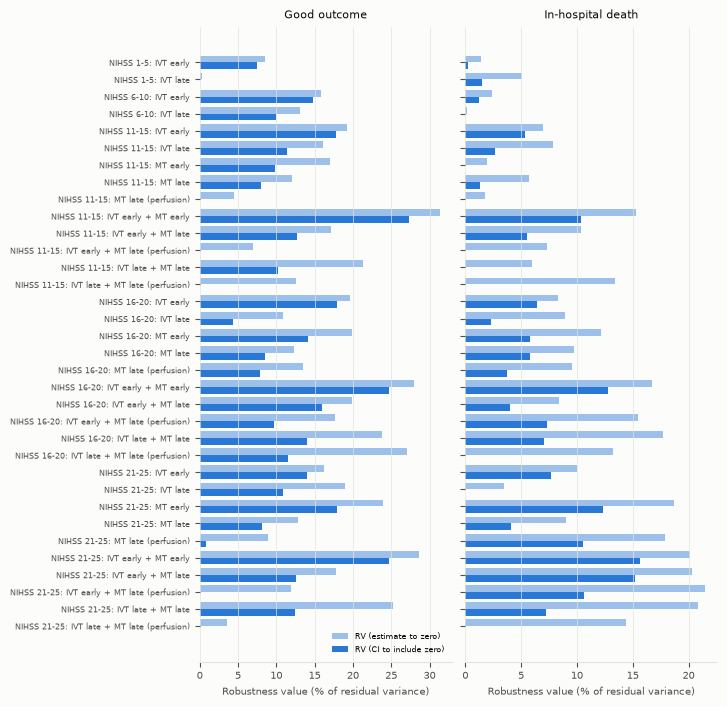

In [ ]:
# Chart: robustness values for each trial group, good outcome and in-hospital death
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_MAX_HEIGHT * 0.9), sharey=True)
group_order = (sensemakr_stats[["group_id", "group_name"]].drop_duplicates()
               .sort_values("group_id", ascending=False))
y = np.arange(len(group_order))
for ax, (outcome, label) in zip(axes, SENSEMAKR_OUTCOMES.items()):
    s = sensemakr_stats[sensemakr_stats["outcome"] == outcome].set_index("group_id").reindex(group_order["group_id"])
    ax.barh(y + 0.2, 100 * s["rv_q"], height=0.4, color=TREATED_COLOUR, alpha=0.45, label="RV (estimate to zero)")
    ax.barh(y - 0.2, 100 * s["rv_qa"], height=0.4, color=TREATED_COLOUR, label="RV (CI to include zero)")
    ax.set_title(label, fontsize=8)
    ax.set_xlabel("Robustness value (% of residual variance)")
    ax.grid(axis="x", color=GRID_COLOUR, linewidth=0.5)
axes[0].set_yticks(y)
axes[0].set_yticklabels(group_order["group_name"], fontsize=6)
axes[0].legend(loc="lower right", fontsize=6, frameon=False)
if SHOW_FIGURE_TITLES:
    fig.suptitle("Sensemakr robustness values")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity_sensemakr_chart.png", dpi=SAVE_DPI)
print(f"Saved chart: {OUTPUT_DIR}/{prefix}_sensitivity_sensemakr_chart.png")
plt.show()

**What this shows:**

* **The regression estimates** are adjusted for the characteristics not used in matching (within-band NIHSS, sex and comorbidities), so they can differ from the primary paired differences. The largest difference is for NIHSS 1–5 early IVT (8.0 vs 3.0 percentage points).
* **Good outcome:** for groups with a clear benefit, an unmeasured confounder would need to explain roughly 8–27% of the remaining variance of both treatment and good outcome to make the confidence interval include zero (RV_q,alpha). The most robust results are for early IVT + early MT (RV_q,alpha 24.7–27.4% across the three NIHSS bands) and early IVT in NIHSS 6–25 (14.0–17.8%). Late MT with perfusion imaging, and several small late-combined groups, already have confidence intervals that include zero.
* **NIHSS 1–5, early IVT is the most fragile benefit.** Within the 1–5 band, treated patients have higher NIHSS than their controls, and NIHSS explains 17.5% of the remaining variation in treatment. Adjusting for it raises the difference from 3.0 percentage points (primary, paired) to 8.0, in line with the exact-NIHSS sensitivity analysis (9.6). However, an unmeasured confounder as strong as within-band NIHSS, acting against treatment, would reduce the difference to 0.4 percentage points, and one three times as strong would reverse it. In the other bands, within-band NIHSS is much less related to treatment: three times its strength changes the IVT-only estimates by less than 3 percentage points, and the MT-based estimates by up to 6 (NIHSS 11–15).
* **In-hospital death:** robustness values are smaller (RV_q,alpha up to 15.7%, for early IVT + early MT in NIHSS 21–25), because death is less common than a good outcome. Reductions in death after MT in NIHSS 16–25 have RV_q,alpha of 4–16%. The small increase in death after IVT in NIHSS 1–5 (0.4 and 1.5 percentage points) is fragile (RV_q,alpha 0.2% and 1.5%).
* As for the E-values, small groups have low RV_q,alpha because their confidence intervals are wide, not necessarily because their estimates are biased.

### Comparison with the primary analysis

One row per outcome and trial group, giving the difference and 95% CI for each analysis. Charts compare good outcome and in-hospital death across analyses. Filled markers show a Holm-adjusted p < 0.05 within that analysis.

**What this cell does:** Brings together all the sensitivity analyses. It saves the full results, builds a table comparing each analysis with the main analysis for every trial group, summarises how often they agree (same direction of effect, statistical significance and median change), and draws comparison charts for good outcome and in-hospital death.

scenario                                                                             Primary  \
outcome        group_id group_name                                                             
death          1        NIHSS 1-5: IVT early                             0.77 (0.47 to 1.08)   
               2        NIHSS 1-5: IVT late                              1.88 (0.91 to 2.84)   
               4        NIHSS 6-10: IVT early                         -0.77 (-1.27 to -0.28)   
               5        NIHSS 6-10: IVT late                            0.27 (-1.30 to 1.84)   
               7        NIHSS 11-15: IVT early                        -4.48 (-5.58 to -3.38)   
...                                                                                      ...   
outcome_target 35       NIHSS 21-25: IVT early + MT early             25.57 (21.59 to 29.56)   
               36       NIHSS 21-25: IVT early + MT late               13.37 (9.01 to 17.73)   
               37       NIHSS 21-25: IVT early + MT late (perfusion)    9.09 (0.18 to 18.00)   
               38       NIHSS 21-25: IVT late + MT late                18.07 (7.91 to 28.23)   
               39       NIHSS 21-25: IVT late + MT late (perfusion)   1.96 (-10.90 to 14.82)   

scenario                                                                         Exact NIHSS  \
outcome        group_id group_name                                                             
death          1        NIHSS 1-5: IVT early                             0.39 (0.06 to 0.71)   
               2        NIHSS 1-5: IVT late                              1.11 (0.02 to 2.20)   
               4        NIHSS 6-10: IVT early                         -1.05 (-1.54 to -0.55)   
               5        NIHSS 6-10: IVT late                            0.00 (-1.55 to 1.55)   
               7        NIHSS 11-15: IVT early                        -4.32 (-5.43 to -3.21)   
...                                                                                      ...   
outcome_target 35       NIHSS 21-25: IVT early + MT early             24.53 (20.35 to 28.72)   
               36       NIHSS 21-25: IVT early + MT late              14.69 (10.66 to 18.72)   
               37       NIHSS 21-25: IVT early + MT late (perfusion)   5.08 (-3.69 to 13.86)   
               38       NIHSS 21-25: IVT late + MT late                14.63 (3.29 to 25.98)   
               39       NIHSS 21-25: IVT late + MT late (perfusion)    6.12 (-2.75 to 14.99)   

scenario                                                                     More covariates  \
outcome        group_id group_name                                                             
death          1        NIHSS 1-5: IVT early                             0.63 (0.31 to 0.94)   
               2        NIHSS 1-5: IVT late                              1.74 (0.71 to 2.76)   
               4        NIHSS 6-10: IVT early                         -0.90 (-1.40 to -0.41)   
               5        NIHSS 6-10: IVT late                            0.20 (-1.30 to 1.71)   
               7        NIHSS 11-15: IVT early                        -4.74 (-5.88 to -3.61)   
...                                                                                      ...   
outcome_target 35       NIHSS 21-25: IVT early + MT early             26.56 (22.33 to 30.79)   
               36       NIHSS 21-25: IVT early + MT late               13.88 (9.37 to 18.38)   
               37       NIHSS 21-25: IVT early + MT late (perfusion)   11.11 (2.61 to 19.62)   
               38       NIHSS 21-25: IVT late + MT late                17.28 (5.97 to 28.59)   
               39       NIHSS 21-25: IVT late + MT late (perfusion)    5.88 (-2.64 to 14.41)   

scenario                                                                          Known onset  \
outcome        group_id group_name                                                              
death          1        NIHSS 1-5: IVT early               

,scenario,outcome,groups,same_direction,significant_primary,significant_sensitivity,median_change
0,Exact NIHSS,outcome_target,34,33,27,25,0.17
1,Exact NIHSS,death,34,33,21,19,-0.35
2,Exact NIHSS,discharge_disability,34,32,30,30,-0.01
3,More covariates,outcome_target,34,33,27,24,-0.34
4,More covariates,death,34,33,21,18,-0.14
5,More covariates,discharge_disability,34,32,30,27,0.02
6,Known onset,outcome_target,34,32,27,22,-1.22
7,Known onset,death,34,32,21,17,0.46
8,Known onset,discharge_disability,34,33,30,28,0.05
9,LVO (MT groups),outcome_target,24,23,18,10,6.48


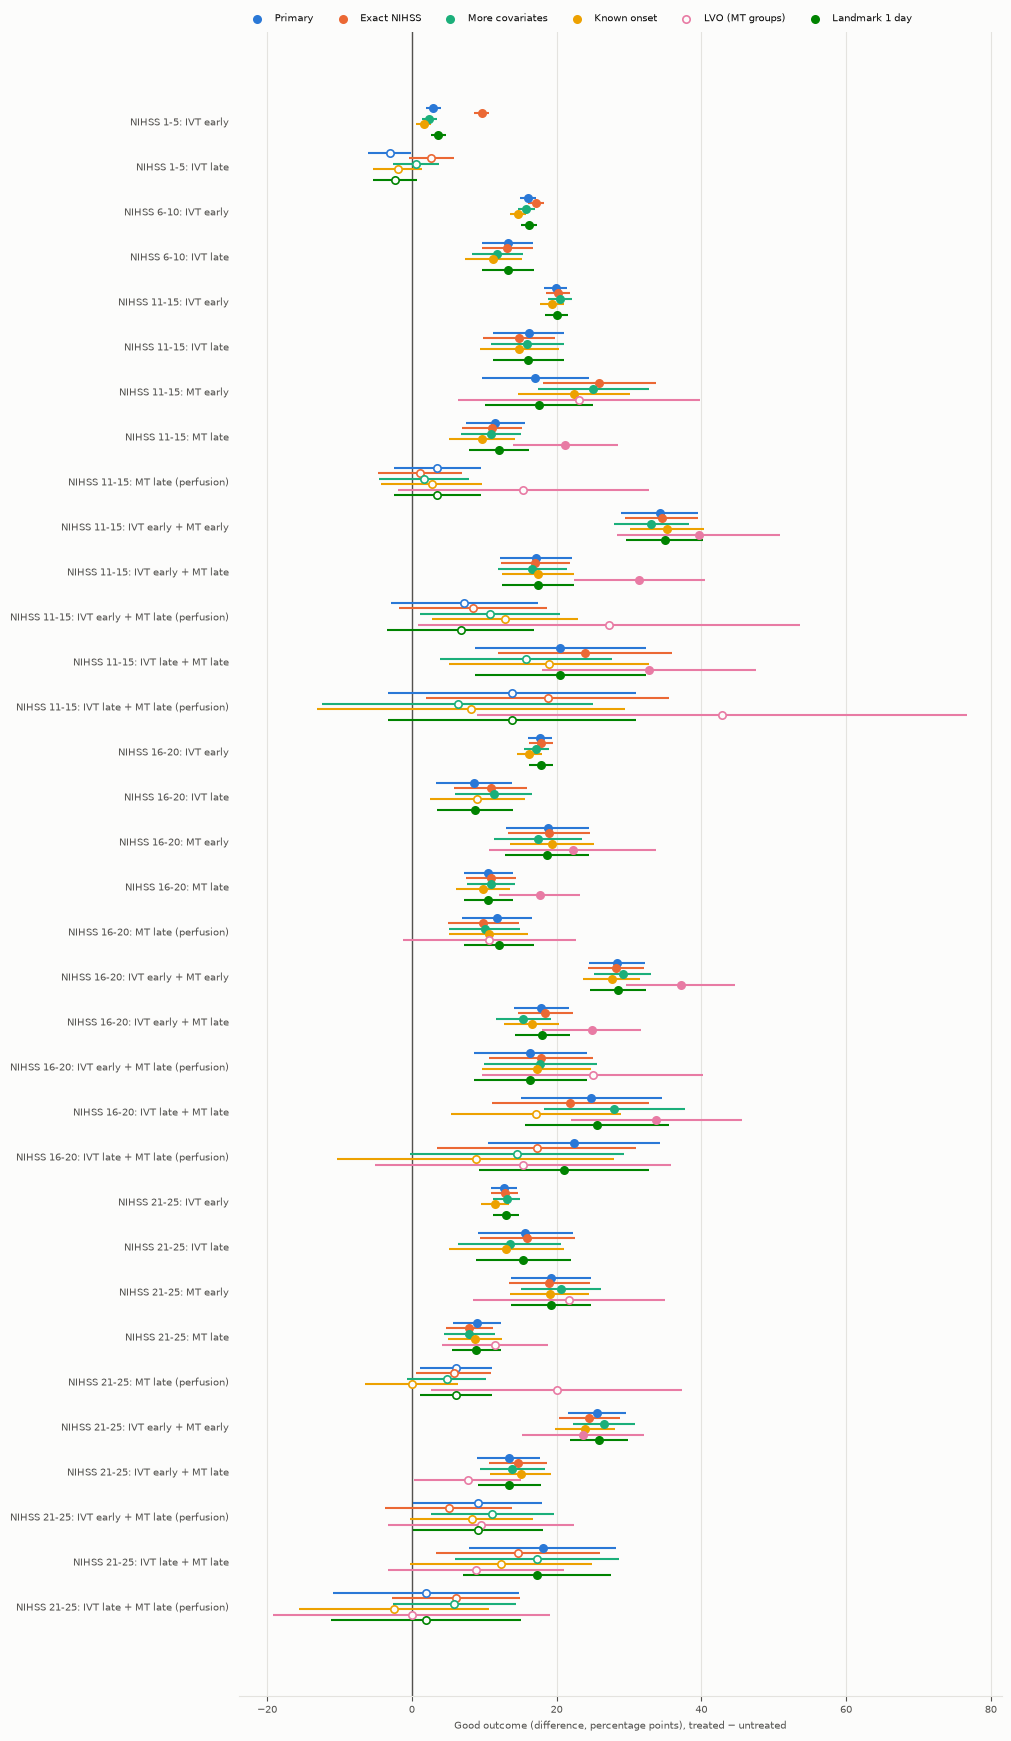

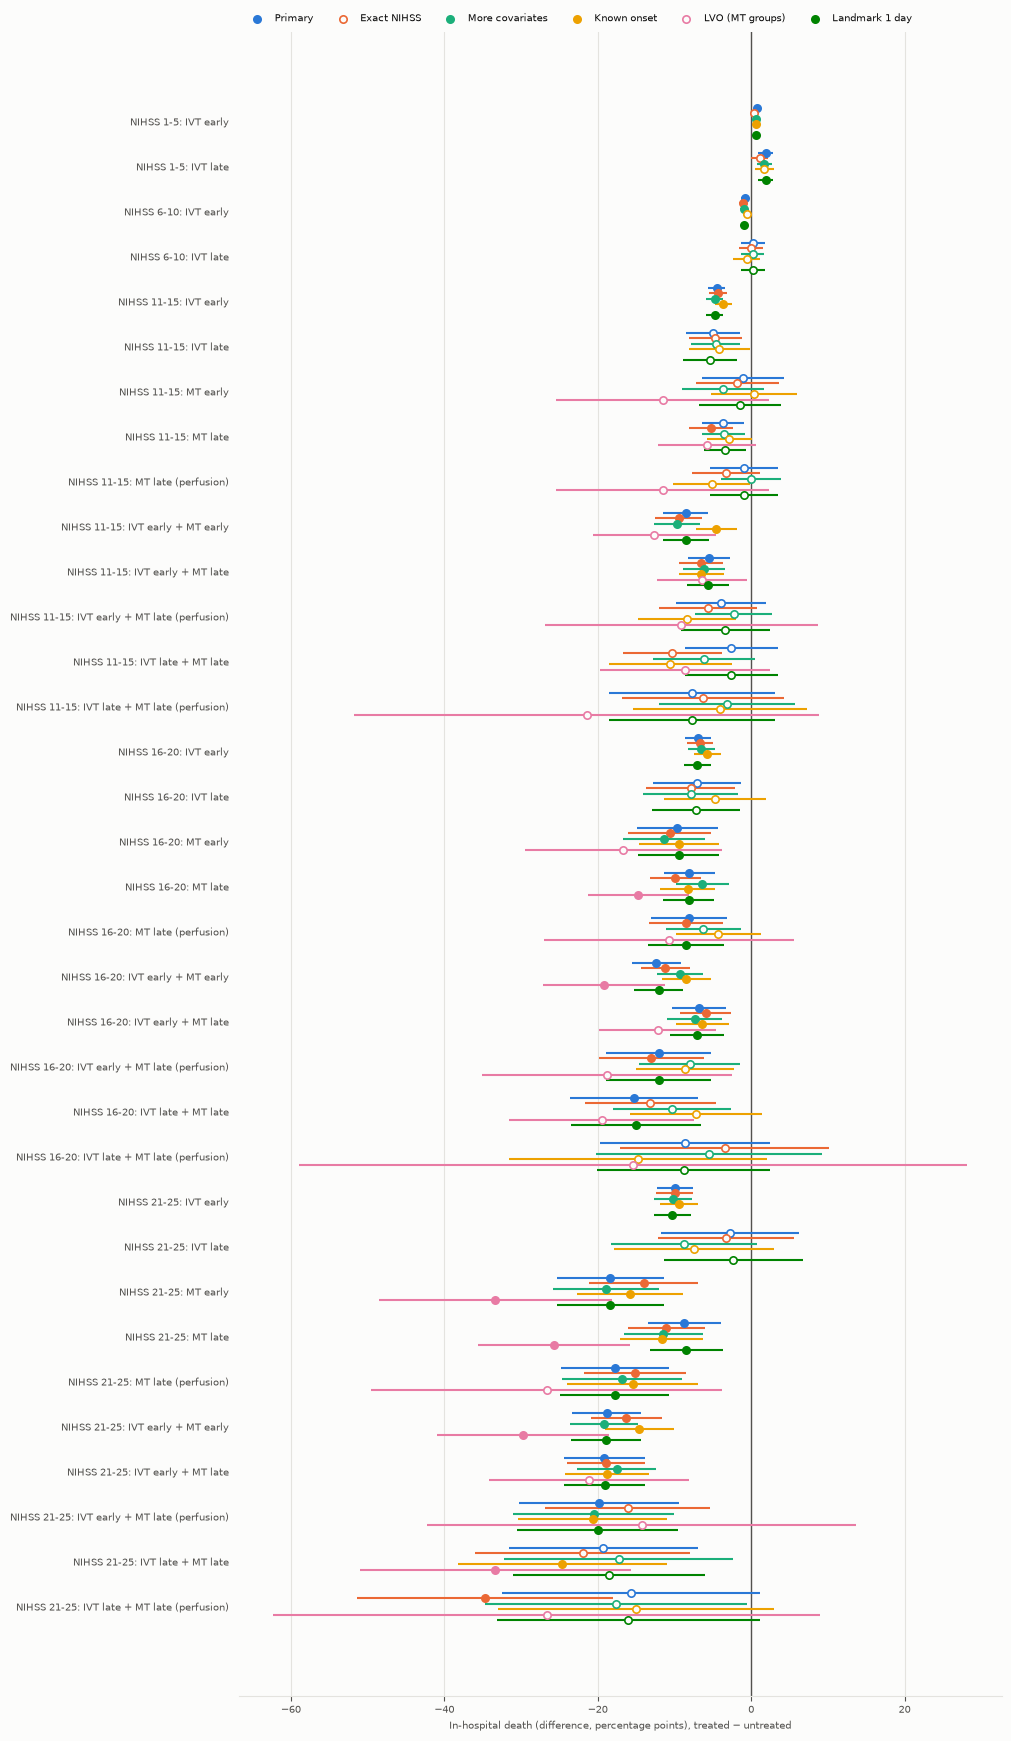

In [24]:
all_sens = pd.concat(sensitivity_results, ignore_index=True)
all_sens.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_all_results.csv", index=False)

for name, s in sensitivity_matching.items():
    s.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_matching_{name.lower().replace(' ', '_').replace('(', '').replace(')', '')}.csv")

all_sens["estimate"] = all_sens.apply(
    lambda r: f"{r['difference']:.2f} ({r['ci_low']:.2f} to {r['ci_high']:.2f})", axis=1)
comparison = all_sens.drop_duplicates(["scenario", "outcome", "group_id"]).pivot_table(
    index=["outcome", "group_id", "group_name"], columns="scenario", values="estimate", aggfunc="first")
scenario_order = ["Primary", "Exact NIHSS", "More covariates", "Known onset", "LVO (MT groups)",
                  "Landmark 1 day", "Survivors"]
comparison = comparison[[s for s in scenario_order if s in comparison.columns]]
comparison.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_comparison.csv")
display(comparison)

# Summary: agreement with the primary analysis
primary = all_sens[all_sens["scenario"] == "Primary"].drop_duplicates(["outcome", "group_id"]).set_index(
    ["outcome", "group_id"])
agree_rows = []
for scenario in [s for s in scenario_order[1:] if s in all_sens["scenario"].unique()]:
    sens = all_sens[all_sens["scenario"] == scenario].set_index(["outcome", "group_id"])
    for outcome in sens.index.get_level_values(0).unique():
        p = primary.loc[outcome] if outcome in primary.index.get_level_values(0) else None
        s = sens.loc[outcome]
        if p is None:
            continue
        common = s.index.intersection(p.index)
        same_dir = (np.sign(s.loc[common, "difference"]) == np.sign(p.loc[common, "difference"])).sum()
        agree_rows.append({
            "scenario": scenario, "outcome": outcome, "groups": len(common),
            "same_direction": int(same_dir),
            "significant_primary": int((p.loc[common, "p_value_holm"] < 0.05).sum()),
            "significant_sensitivity": int((s.loc[common, "p_value_holm"] < 0.05).sum()),
            "median_change": float((s.loc[common, "difference"] - p.loc[common, "difference"]).median()),
        })
agreement = pd.DataFrame(agree_rows)
agreement.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_agreement.csv", index=False)
display(agreement.style.format(precision=2))


def plot_sensitivity(outcome, scenarios, path):
    res = all_sens[(all_sens["outcome"] == outcome) & (all_sens["scenario"].isin(scenarios))]
    groups = (res[res["scenario"] == "Primary"][["group_id", "group_name"]]
              .drop_duplicates().sort_values("group_id"))
    n_s = len(scenarios)
    offsets = np.linspace(0.3, -0.3, n_s) if n_s > 1 else [0]
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(groups) + 2), layout="constrained")
    for k, scenario in enumerate(scenarios):
        r = res[res["scenario"] == scenario].set_index("group_id")
        labelled = False
        for g, (gid, _) in enumerate(groups.itertuples(index=False)):
            if gid not in r.index:
                continue
            row = r.loc[gid]
            y = -g + offsets[k]
            colour = CATEGORY_COLOURS[k % len(CATEGORY_COLOURS)]
            ax.hlines(y, row["ci_low"], row["ci_high"], color=colour, lw=1.5, zorder=2)
            filled = row["p_value_holm"] < 0.05
            ax.scatter(row["difference"], y, s=28, zorder=3, color=colour if filled else SURFACE,
                       edgecolor=colour, linewidth=1.2, label=None if labelled else scenario)
            labelled = True
    ax.axvline(0, color=TEXT_SECONDARY, lw=1, zorder=1)
    ax.set_yticks(-np.arange(len(groups)), groups["group_name"])
    ax.set_xlabel(SENS_OUTCOME_LABELS[outcome] + ", treated − untreated")
    ax.grid(axis="x", color=GRID_COLOUR, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(left=False)
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), loc="lower left", bbox_to_anchor=(0, 1),
              ncol=min(n_s, 6), frameon=False)
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches="tight")
    plt.show()


chart_scenarios = [s for s in scenario_order[:-1] if s in all_sens["scenario"].unique()]
for outcome in ["outcome_target", "death"]:
    plot_sensitivity(outcome, chart_scenarios, f"{OUTPUT_DIR}/{prefix}_sensitivity_{outcome}_chart.png")